# Avance 2: Exploración de los datos y regresión lineal múltiple

Proyecto: determinantes de las estadías prolongadas en beneficiarios FONASA (Chile, 2020)

**Resumen.** Usamos los mismos 968.098 egresos FONASA de 2020 del Avance 1. Ajustamos una regresión lineal múltiple de ln(días de estada) y una regresión logística para la estadía prolongada, con las 7 variables que eligió el BIC. Entrenamos con 677.669 egresos (70 %) y evaluamos con 290.429 (30 %):

- El modelo explica el 19,8 % de la variabilidad de ln(días), tanto en entrenamiento como en test (R² ajustado = 0,198 en los dos). No hay sobreajuste.
- El capítulo CIE-10 es el factor más asociado a la duración. Frente al digestivo (K00-K93), la mediana de días de los trastornos mentales (F00-F99) es 213 % mayor y la de las enfermedades del ojo (H00-H59), 32 % menor.
- Con el criterio del Avance 1 (significativo y efecto al menos pequeño, η² ≥ 0,01; Cohen, 1988), son relevantes el capítulo (η² parcial = 0,074, mediano), el establecimiento (0,041) y la edad (0,035), estos dos pequeños. Región, sexo, condición de egreso y cirugía son significativos, pero quedan bajo el umbral. El bloque clínico completo tiene η² = 0,132 (mediano).
- En días, exp(ŷ) estima la mediana, y el MAE en test es 4,67 contra 5,03 de predecir siempre la mediana (3.4).
- Mejoramos M3 donde fallaba (edad en tramos e interacciones, M4 a M6): el R² ajustado sube de 0,198 a 0,215 y el MAE en días baja de 4,67 a 4,63. Es una mejora pequeña, y creemos que falta información de gravedad que la base no trae (3.8).
- Para la estadía prolongada ajustamos una regresión logística: AUC de 0,770 en test, con el establecimiento SNSS (OR = 2,55) y el capítulo como factores principales (3.9).
- Los errores del modelo lineal tienen varianza no constante (se ve en los residuos), así que sus valores-p e intervalos son aproximados.

Fuente de todas las tablas y figuras: DEIS (MINSAL), egresos hospitalarios 2020; elaboración propia.

## 1. Pregunta de investigación e hipótesis

La pregunta y las hipótesis son las del Avance 1.

> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía y con las estadías prolongadas (más de 15 días) en los egresos FONASA de Chile en 2020?

**Hipótesis general**

- H₀: la duración de la estadía y la ocurrencia de estadías prolongadas no se asocian con los factores clínicos, demográficos ni del sistema de salud.
- H₁: al menos uno de esos factores se asocia con la duración de la estadía o con la ocurrencia de estadías prolongadas.

Hipótesis específicas, una por grupo de factores:

| | Factores | H₁ |
|---|---|---|
| H1a | Clínicos: capítulo del diagnóstico (CIE-10), cirugía y condición de egreso | Se asocian a la duración y a la estadía prolongada |
| H1b | Demográficos: edad, sexo, nacionalidad y etnia | Se asocian a la duración y a la estadía prolongada (esperamos más días a mayor edad) |
| H1c | Sistema de salud: tipo de establecimiento y región | Se asocian a la duración y a la estadía prolongada |

Qué cambia en este avance: el Avance 1 comparó los factores de a pares. Aquí los metemos juntos en un modelo de ln(días) con las 7 variables que eligió el BIC, para ver cuánto se asocia cada uno cuando controlamos por los demás. Nacionalidad y etnia quedaron fuera por el BIC (sección 5.6 del Avance 1). El modelo lineal responde la duración (3.1 a 3.8). La estadía prolongada, que el Avance 1 solo vio de a pares, la respondemos con una regresión logística, que vimos en el curso (3.9). Juzgamos la relevancia con el criterio del Avance 1: significativo y con efecto al menos pequeño (Cohen, 1988), medido con η² parcial (3.2). En la logística ordenamos los factores por cuánto cae el D² de McFadden al sacarlos.

## 2. Exploración y preparación de los datos

El curso propone cinco etapas: análisis descriptivo, ajuste de variables, valores nulos, valores atípicos y relación entre variables. Las seguimos en ese orden. Primero cargamos los datos con el código del Avance 1.

### Paso 1: cargar los datos

Solo FONASA (`PREVISION = 1`) y estadías de hasta 365 días. Los 397 egresos de más de un año son errores de registro, como en el Avance 1. Los atípicos de Tukey entre 15 y 365 días sí los conservamos, porque son estadías reales (etapa 4).

In [1]:
import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
teal, petroleo, coral = "#0E7C7A", "#0F2A33", "#D9534F"

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
print("Egresos 2020:", len(df))

df = df[df["PREVISION"] == "1"]                      # solo FONASA
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
bruta = df["dias_estada"].copy()                     # con los de más de 365 días, para compararlos en la etapa 4
print("Estadías de más de 365 días:", (df["dias_estada"] > 365).sum(), "| máximo:", df["dias_estada"].max(), "días")
df = df[df["dias_estada"] <= 365].copy()             # quitamos errores de registro
print("Egresos FONASA con estada <= 365 días:", len(df))


Egresos 2020: 1330477


Estadías de más de 365 días: 397 | máximo: 16598 días
Egresos FONASA con estada <= 365 días: 968098


Quedan 968.098 egresos, el mismo número del Avance 1.

### Paso 2: construir las variables

Reutilizamos los mapeos del Avance 1: la edad es el punto medio de cada tramo, el capítulo CIE-10 viene del diccionario del DEIS, `INTERV_Q` 1/2 es cirugía Sí/No y `CONDICION_EGRESO` 1/2 es vivo/fallecido. Nos quedamos con la respuesta, los 7 predictores y `DIAG2` (para revisar sus nulos), y agregamos ln(días).

In [2]:
edad_media = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()

df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["tramo_edad"] = df["GRUPO_EDAD"]
df["sexo"] = df["SEXO"]
df["capitulo"] = df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
df["fallecido"] = df["CONDICION_EGRESO"].map({"1": "No", "2": "Sí"})
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"]
df["nacionalidad"] = df["GLOSA_PAIS_ORIGEN"]
df["etnia"] = np.where(df["ETNIA"].str.startswith("Si"), "Sí", "No")
df["log_dias"] = np.log(df["dias_estada"])

variables = ["dias_estada", "log_dias", "prolongada", "edad", "tramo_edad", "sexo", "capitulo", "cirugia",
             "fallecido", "establecimiento", "region", "nacionalidad", "etnia", "DIAG2"]
df = df[variables]
print("Egresos:", len(df), "| columnas:", df.shape[1])
df.head()


Egresos: 968098 | columnas: 14


,dias_estada,log_dias,prolongada,edad,tramo_edad,sexo,capitulo,cirugia,fallecido,establecimiento,region,nacionalidad,etnia,DIAG2
0,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
1,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
2,1,0.0,No,5.0,1 a 9,HOMBRE,Z00-Z99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
3,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
4,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN


### Etapa 1: análisis descriptivo

**Tabla 1.** Estadísticos descriptivos de los días de estada, ln(días) y la edad. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [3]:
cols = ["dias_estada", "log_dias", "edad"]
desc = df[cols].agg(["count", "mean", "median"]).T
desc["Q1"] = df[cols].quantile(0.25)
desc["Q3"] = df[cols].quantile(0.75)
desc["RIC"] = desc["Q3"] - desc["Q1"]
desc["s"] = df[cols].std()
desc["CV"] = desc["s"] / desc["mean"]
desc["asimetría"] = df[cols].skew()
desc.round(2)


,count,mean,median,Q1,Q3,RIC,s,CV,asimetría
dias_estada,968098.0,6.70,3.0,2.00,7.00,5.00,12.79,1.91,9.04
log_dias,968098.0,1.25,1.1,0.69,1.95,1.25,1.04,0.83,0.68
edad,968098.0,45.01,44.5,24.50,64.50,40.00,24.29,0.54,0.01


Los días de estada tienen media 6,70 y mediana 3 (Q1 = 2, Q3 = 7, RIC = 5). La desviación estándar (12,79) casi duplica la media (CV = 1,91) y la asimetría es 9,04: la mayoría dura pocos días y unos pocos duran muchísimo. En ln(días) la asimetría baja a 0,68 y la media (1,25) queda cerca de la mediana (1,10), por eso modelamos el logaritmo. La edad es simétrica (asimetría 0,01; media 45,01; mediana 44,5; Q1 = 24,5; Q3 = 64,5).

In [4]:
for var in ["establecimiento", "sexo"]:
    print((100 * df[var].value_counts(normalize=True)).round(1).to_string(), "\n")
cap = 100 * df["capitulo"].value_counts(normalize=True)
print("Capítulos más frecuentes (%):")
print(cap.head(6).round(1).to_string())
print(f"Los otros {len(cap) - 6} capítulos juntos:", round(cap.iloc[6:].sum(), 1), "%")


establecimiento
SNSS       81.8
No SNSS    18.2 

sexo
MUJER     60.0
HOMBRE    40.0 

Capítulos más frecuentes (%):
capitulo
O00-O99    20.4
K00-K93    13.8
S00-T98     9.8
I00-I99     9.3
N00-N99     7.6
C00-D48     7.4
Los otros 15 capítulos juntos: 31.7 %


El 81,8 % de los egresos son de establecimientos del SNSS y el 60,0 % son mujeres. Los capítulos más frecuentes son embarazo, parto y puerperio (O00-O99, 20,4 %), digestivo (K00-K93, 13,8 %) y traumatismos (S00-T98, 9,8 %). Los otros 15 suman el 31,7 %.

**Figura 1.** Distribución de los días de estada (izquierda, recortada a 60 días), de ln(días) (centro) y curva de concentración de los días-cama (derecha).

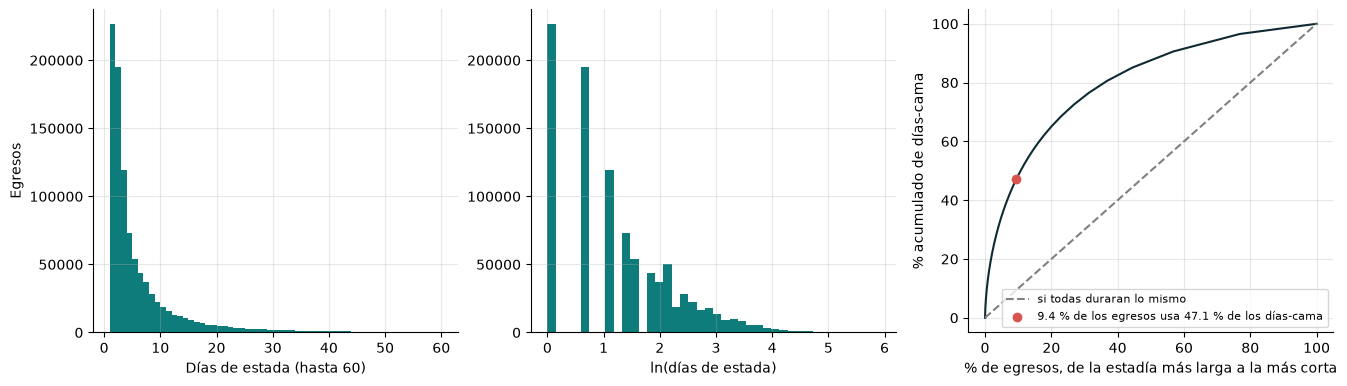

Media: 6.7 | mediana: 3.0 | egresos prolongados: 9.4 % | días-cama que usan: 47.1 %


In [5]:
largas = df["prolongada"] == "Sí"
pct_egresos = 100 * largas.mean()
pct_dias = 100 * df.loc[largas, "dias_estada"].sum() / df["dias_estada"].sum()

orden = np.sort(df["dias_estada"].values)[::-1]                 # de la estadía más larga a la más corta
x_conc = 100 * np.arange(1, len(orden) + 1) / len(orden)
y_conc = 100 * orden.cumsum() / orden.sum()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(df["dias_estada"], bins=range(1, 61), color=teal)
ax[0].set_xlabel("Días de estada (hasta 60)")
ax[0].set_ylabel("Egresos")
ax[1].hist(df["log_dias"], bins=40, color=teal)
ax[1].set_xlabel("ln(días de estada)")
ax[2].plot(x_conc[::500], y_conc[::500], color=petroleo)
ax[2].plot([0, 100], [0, 100], color="gray", linestyle="--", label="si todas duraran lo mismo")
ax[2].scatter([pct_egresos], [pct_dias], color=coral, zorder=3,
              label=f"{pct_egresos:.1f} % de los egresos usa {pct_dias:.1f} % de los días-cama")
ax[2].set_xlabel("% de egresos, de la estadía más larga a la más corta")
ax[2].set_ylabel("% acumulado de días-cama")
ax[2].legend(loc="lower right", fontsize=8)
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/avance2_distribucion.png", dpi=200, bbox_inches="tight")
plt.show()
print("Media:", round(df["dias_estada"].mean(), 1), "| mediana:", df["dias_estada"].median(),
      "| egresos prolongados:", round(pct_egresos, 1), "% | días-cama que usan:", round(pct_dias, 1), "%")


El histograma de días tiene cola larga: la moda es 1 día (226.248 egresos), seguida de 2 días (194.873) y 3 días (119.440). En ln(días) las barras quedan separadas porque los días son enteros (ln 1 = 0, ln 2 = 0,69, ln 3 = 1,10), y la cola derecha es más corta. La curva de la derecha muestra que el 9,4 % de los egresos (los de más de 15 días) usa el 47,1 % de los días-cama (estadías de hasta 365 días). Esos pocos egresos largos pesan mucho en la gestión de camas, así que queremos entender qué se asocia con la duración.

### Etapa 2: ajuste de variables

| Variable | Tipo | Codificación | Referencia |
|---|---|---|---|
| ln(días) | Numérica, respuesta | Logaritmo natural de `DIAS_ESTADA` | |
| Edad | Numérica | `edad_c` = punto medio del tramo − media, y `edad_c`² | Edad media (0) |
| Capítulo CIE-10 | Categórica (21) | 20 indicadoras | K00-K93 |
| Cirugía | Categórica | Indicadora de Sí | No |
| Condición de egreso | Categórica | Indicadora de fallecido | Vivo |
| Sexo | Categórica | Indicadora de hombre | Mujer |
| Establecimiento | Categórica | Indicadora de SNSS | No SNSS |
| Región | Categórica (16) | 15 indicadoras | Metropolitana de Santiago |

En el Avance 1 centramos la edad en 50 para que edad y edad² no quedaran colineales en la selección por BIC. Aquí la centramos en su media, así el intercepto corresponde a un paciente de edad promedio. Es solo un cambio de origen y el ajuste es el mismo.

En sexo la referencia es la mujer, para expresar el coeficiente como hombres frente a mujeres. Así respondemos lo que el Avance 1 dejó pendiente: si la diferencia por sexo se mantiene al controlar por diagnóstico. La respuesta está en 3.3: sí se mantiene (+11,4 %). Cambiar la referencia solo cambia el signo y la lectura del coeficiente.

Como capítulo de referencia usamos K00-K93 en vez de O00-O99, que en el Avance 1 usamos solo para la selección. O00-O99 es solo de mujeres, y el coeficiente de sexo se mezclaría con el del capítulo. K00-K93 tiene hombres y mujeres y una mediana baja (2 días), así que los demás coeficientes son diferencias respecto de un egreso corto y habitual.

In [6]:
edad_prom = df["edad"].mean()
df["edad_c"] = df["edad"] - edad_prom
print("Edad media (el cero de edad_c):", round(edad_prom, 2))
k = df[df["capitulo"] == "K00-K93"]
print("Capítulo K00-K93:", round(100 * len(k) / len(df), 1), "% de los egresos | mediana:", k["dias_estada"].median(),
      "días | sexo (% mujeres):", round(100 * (k["sexo"] == "MUJER").mean(), 1))
print("Valores de sexo:", sorted(df["sexo"].unique()))


Edad media (el cero de edad_c): 45.01
Capítulo K00-K93: 13.8 % de los egresos | mediana: 2.0 días | sexo (% mujeres): 53.6
Valores de sexo: ['HOMBRE', 'MUJER']


La edad media es 45,01 años. K00-K93 es el 13,8 % de los egresos, con una mediana de 2 días y un 53,6 % de mujeres, así que sirve como referencia sin confundir el sexo.

### Etapa 3: valores nulos

In [7]:
usadas = ["dias_estada", "edad", "sexo", "capitulo", "cirugia", "fallecido", "establecimiento", "region", "DIAG2"]
print(df[usadas].isna().sum().to_string())
pct_diag2 = 100 * df["DIAG2"].isna().mean()
print("DIAG2 nulo:", round(pct_diag2, 1), "% de los egresos")


dias_estada             0
edad                    0
sexo                    0
capitulo                0
cirugia                 0
fallecido               0
establecimiento         0
region                  0
DIAG2              872823
DIAG2 nulo: 90.2 % de los egresos


Las variables de la respuesta y de los 7 predictores no tienen nulos, así que no imputamos ni eliminamos egresos. `DIAG2` tiene un 90,2 % de nulos. En el Avance 1 vimos que solo aparece en el capítulo S00-T98, con una V de Cramér de 1,00: repite información del capítulo. Por eso la descartamos.

### Etapa 4: valores atípicos

Usamos el criterio de Tukey (Ls = Q3 + 1,5·RIC) y el de |z| > 3, sobre días y ln(días). Comparamos también media y desviación estándar con mediana y MAD (mediana de las desviaciones absolutas respecto de la mediana), antes y después del filtro de 365 días.

**Tabla 2.** Límites de Tukey y de |z| > 3 para los días y ln(días) (primera salida). **Tabla 3.** Media, desviación estándar, mediana y MAD antes y después de excluir los egresos de más de 365 días (segunda salida). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [8]:
filas = []
for nombre, x in [("días", df["dias_estada"]), ("ln(días)", df["log_dias"])]:
    q1, q3 = x.quantile([0.25, 0.75])
    li, ls = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    z = (x - x.mean()) / x.std()
    filas.append({"variable": nombre, "Li": li, "Ls": ls, "n > Ls": (x > ls).sum(), "% > Ls": 100 * (x > ls).mean(),
                  "n < Li": (x < li).sum(), "n |z| > 3": (z.abs() > 3).sum(), "% |z| > 3": 100 * (z.abs() > 3).mean()})
atip = pd.DataFrame(filas).set_index("variable")
print(atip.round(2).to_string())

comp = pd.DataFrame({"n": [len(bruta), len(df), len(df)]}, index=["días con > 365 incluidos", "días (base final)", "ln(días)"])
series = [bruta, df["dias_estada"], df["log_dias"]]
comp["media"] = [x.mean() for x in series]
comp["s"] = [x.std() for x in series]
comp["mediana"] = [x.median() for x in series]
comp["MAD"] = [(x - x.median()).abs().median() for x in series]
comp.round(2)


            Li     Ls  n > Ls  % > Ls  n < Li  n |z| > 3  % |z| > 3
variable                                                           
días     -5.50  14.50   99978   10.33       0      14614       1.51
ln(días) -1.19   3.83   14614    1.51       0       4745       0.49


,n,media,s,mediana,MAD
días con > 365 incluidos,968495,7.29,59.74,3.0,2.00
días (base final),968098,6.70,12.79,3.0,2.00
ln(días),968098,1.25,1.04,1.1,0.69


Con Tukey, el límite superior de los días es 14,5 y lo superan 99.978 egresos (10,33 %). Con |z| > 3 son 14.614 (1,51 %). En ln(días) el límite sube a 3,83 (unos 46 días) y lo superan 14.614 egresos (1,51 %); con |z| > 3 son 4.745 (0,49 %). Por abajo no hay ninguno, porque el mínimo es 1 día. Que en ln(días) sigan apareciendo atípicos según Tukey se debe a que la cola derecha sigue siendo más larga.

La comparación muestra por qué filtramos los 397 egresos de más de 365 días: con ellos, la media sube de 6,70 a 7,29 y la desviación estándar de 12,79 a 59,74, mientras la mediana (3) y el MAD (2) no cambian. Unos pocos registros imposibles mueven la media y s, pero no las medidas basadas en la mediana.

**Figura 2.** Diagrama de caja de los días de estada (izquierda) y de ln(días) (derecha). La línea roja marca Q3 + 1,5·RIC.

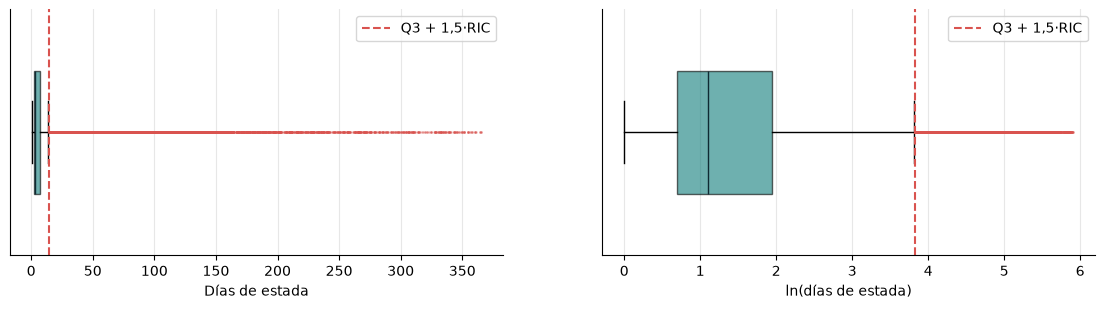

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
for a, col, titulo in zip(ax, ["dias_estada", "log_dias"], ["Días de estada", "ln(días de estada)"]):
    a.boxplot(df[col], orientation="horizontal", widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo),
              flierprops=dict(marker=".", markersize=2, markerfacecolor=coral, markeredgecolor=coral, alpha=0.3))
    a.axvline(atip.loc["días" if col == "dias_estada" else "ln(días)", "Ls"], color=coral, linestyle="--", label="Q3 + 1,5·RIC")
    a.set_xlabel(titulo)
    a.set_yticks([])
    a.legend()
fig.savefig("figures/avance2_atipicos.png", dpi=200, bbox_inches="tight")
plt.show()


En días, la caja está pegada a la izquierda y los puntos rojos llegan hasta 365 días, el máximo que dejamos. En ln(días) la caja es simétrica y los puntos forman una cola más corta. Conservamos los egresos de 15 a 365 días: son estadías reales y son el fenómeno que queremos estudiar, porque son los que más días-cama usan. Excluimos los de más de 365 días porque son errores de registro (el máximo es 16.598 días, unos 45 años). Modelamos ln(días), que reduce la influencia de estos valores en los coeficientes, y revisamos sus residuos en 3.6.

### Etapa 5: relación entre variables

Antes de ver si los predictores se repiten entre sí, miramos cómo cambia ln(días) según los tres factores con más diferencia en el Avance 1: capítulo, establecimiento y sexo.

/tmp/ipykernel_79995/4097549973.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax0.boxplot([df.loc[df["capitulo"] == k, "log_dias"] for k in orden_cap], vert=False, showfliers=False,
/tmp/ipykernel_79995/4097549973.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df.loc[df[col] == n, "log_dias"] for n in niv], vert=False, showfliers=False,
/tmp/ipykernel_79995/4097549973.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df.loc[df[col] == n, "log_dias"] for n in niv], vert=False, showfliers=False,


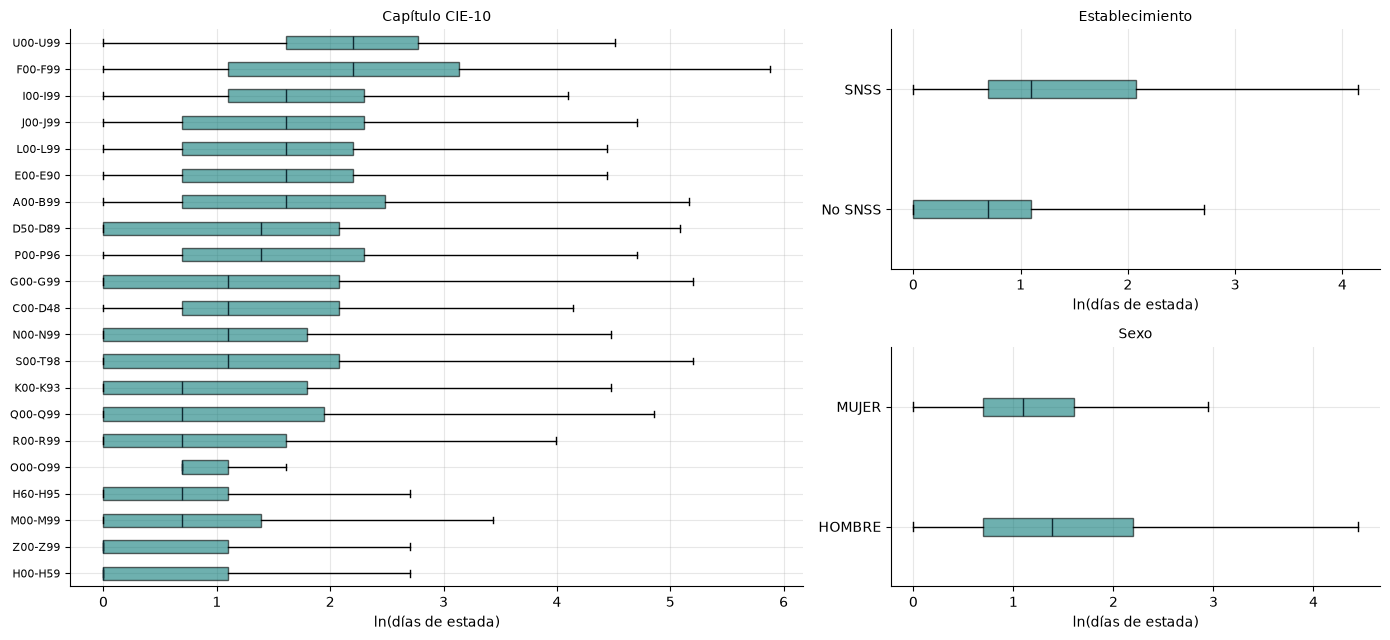

Mediana de días por capítulo: mínima 1.0 (H00-H59), máxima 9.0 (U00-U99)
Mediana de días por establecimiento: {'No SNSS': 2.0, 'SNSS': 3.0}
Mediana de días por sexo: {'HOMBRE': 4.0, 'MUJER': 3.0}
Mediana de días por cirugía: {'No': 4.0, 'Sí': 2.0} | por condición de egreso: {'No': 3.0, 'Sí': 7.0}


In [10]:
orden_cap = df.groupby("capitulo")["log_dias"].median().sort_values().index
fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.5, 1])
ax0 = fig.add_subplot(gs[:, 0])
ax0.boxplot([df.loc[df["capitulo"] == k, "log_dias"] for k in orden_cap], vert=False, showfliers=False,
            patch_artist=True, boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo))
ax0.set_yticks(range(1, len(orden_cap) + 1), orden_cap, fontsize=8)
ax0.set_xlabel("ln(días de estada)")
ax0.set_title("Capítulo CIE-10", fontsize=10)
for ax, col, tit in [(fig.add_subplot(gs[0, 1]), "establecimiento", "Establecimiento"),
                     (fig.add_subplot(gs[1, 1]), "sexo", "Sexo")]:
    niv = sorted(df[col].unique())
    ax.boxplot([df.loc[df[col] == n, "log_dias"] for n in niv], vert=False, showfliers=False,
               patch_artist=True, boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo))
    ax.set_yticks(range(1, len(niv) + 1), niv)
    ax.set_xlabel("ln(días de estada)")
    ax.set_title(tit, fontsize=10)
fig.tight_layout()
fig.savefig("figures/avance2_bivariado.png", dpi=200, bbox_inches="tight")
plt.show()
med = df.groupby("capitulo")["dias_estada"].median().sort_values()
print("Mediana de días por capítulo: mínima", med.iloc[0], "(" + med.index[0] + "), máxima", med.iloc[-1], "(" + med.index[-1] + ")")
print("Mediana de días por establecimiento:", df.groupby("establecimiento")["dias_estada"].median().to_dict())
print("Mediana de días por sexo:", df.groupby("sexo")["dias_estada"].median().to_dict())
print("Mediana de días por cirugía:", df.groupby("cirugia")["dias_estada"].median().to_dict(),
      "| por condición de egreso:", df.groupby("fallecido")["dias_estada"].median().to_dict())

**Figura 3.** Distribución de ln(días) por capítulo CIE-10 (ordenados por mediana), por tipo de establecimiento y por sexo. Sin puntos atípicos, para ver las cajas. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

Las cajas se mueven bastante entre capítulos: la mediana de días va de 1 (H00-H59, ojo) a 9 (U00-U99, uso especial), y la de F00-F99 queda también arriba. Entre establecimientos la diferencia es más corta (mediana de 3 días en el SNSS contra 2 fuera del SNSS), y entre sexos también (4 días en hombres contra 3 en mujeres). Esto anticipa el orden del modelo: el capítulo separa mucho más los egresos que el establecimiento o el sexo. Cirugía y condición de egreso tienen medianas de 2 y 4 días (con y sin cirugía) y de 7 y 3 días (fallecido y vivo), pero la mayor parte de esa diferencia se achica al controlar por el diagnóstico (3.7).

Para ver si los predictores categóricos se repiten entre sí, calculamos la V de Cramér entre todos los pares. La edad queda fuera por ser numérica.

capitulo  cirugia            0.429
          sexo               0.428
cirugia   establecimiento    0.283
capitulo  fallecido          0.261
          establecimiento    0.190
% de egresos con cirugía por capítulo: mínimo 0.7 (F00-F99), máximo 75.0 (M00-M99)
% de mujeres en O00-O99: 100.0


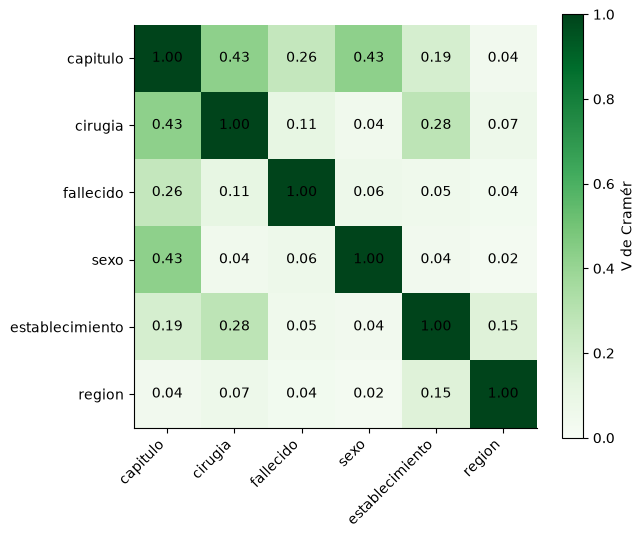

In [11]:
cats = ["capitulo", "cirugia", "fallecido", "sexo", "establecimiento", "region"]
V = pd.DataFrame(1.0, index=cats, columns=cats)
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        tabla = pd.crosstab(df[a], df[b])
        chi2 = stats.chi2_contingency(tabla)[0]
        V.loc[a, b] = V.loc[b, a] = np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1)))

pares = V.where(~np.eye(len(cats), dtype=bool)).stack()
pares = pares[[a < b for a, b in pares.index]].sort_values(ascending=False)
print(pares.round(3).head(5).to_string())
cir = 100 * df.groupby("capitulo")["cirugia"].apply(lambda s: (s == "Sí").mean())
print("% de egresos con cirugía por capítulo: mínimo", round(cir.min(), 1), "(" + cir.idxmin() + "), máximo", round(cir.max(), 1), "(" + cir.idxmax() + ")")
print("% de mujeres en O00-O99:", round(100 * (df.loc[df["capitulo"] == "O00-O99", "sexo"] == "MUJER").mean(), 1))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(V, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(cats)), cats, rotation=45, ha="right")
ax.set_yticks(range(len(cats)), cats)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, f"{V.iloc[i, j]:.2f}", ha="center", va="center", color="black")
ax.grid(False)
fig.colorbar(im, label="V de Cramér")
fig.savefig("figures/avance2_cramer.png", dpi=200, bbox_inches="tight")
plt.show()


**Figura 4.** V de Cramér entre los predictores categóricos.

El máximo es 0,43 (capítulo y cirugía), seguido de capítulo y sexo (0,43) y cirugía y establecimiento (0,28). Es una asociación mediana según Cohen (1988) y tiene sentido: la proporción con cirugía va de 0,7 % (F00-F99) a 75,0 % (M00-M99), y O00-O99 es solo de mujeres. No llega a la redundancia de `DIAG2`, y lo confirmamos con el VIF en 3.6. Mantenemos las tres variables.

Ahora separamos los datos: el 70 % para entrenar (`df.sample(frac=0.7, random_state=1)`) y el resto para evaluar.

**Tabla 4.** Balance entre entrenamiento y test. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [12]:
train = df.sample(frac=0.7, random_state=1).copy()
test = df.drop(train.index).copy()
balance = pd.DataFrame({
    "egresos": [len(train), len(test)],
    "media de días": [d["dias_estada"].mean() for d in (train, test)],
    "mediana de días": [d["dias_estada"].median() for d in (train, test)],
    "% prolongadas": [100 * (d["prolongada"] == "Sí").mean() for d in (train, test)],
    "% SNSS": [100 * (d["establecimiento"] == "SNSS").mean() for d in (train, test)],
    "% fallecidos": [100 * (d["fallecido"] == "Sí").mean() for d in (train, test)],
    "edad media": [d["edad"].mean() for d in (train, test)],
}, index=["train", "test"])
balance.round(2)


,egresos,media de días,mediana de días,% prolongadas,% SNSS,% fallecidos,edad media
train,677669,6.71,3.0,9.40,81.84,3.84,45.01
test,290429,6.69,3.0,9.37,81.86,3.89,45.02


Entrenamiento y test quedan casi iguales en media de días (6,71 y 6,69), porcentaje de estadías prolongadas (9,40 % y 9,37 %), de SNSS (81,84 % y 81,86 %), de fallecidos (3,84 % y 3,89 %) y edad media (45,01 y 45,02). Por eso una diferencia entre métricas de entrenamiento y test no se puede atribuir a que las muestras sean distintas.

## 3. Resultados y modelamiento

### 3.1 Modelo propuesto en el Avance 1

Proponíamos una regresión lineal múltiple de ln(días) con 7 variables explicativas, evaluada con R² ajustado, MAE y RMSE sobre el 30 % de test:

$$\ln(\text{días}_i) = \beta_0 + \sum_{c}\gamma_c\,\text{capítulo}_{ic} + \beta_1\,\text{cirugía}_i + \beta_2\,\text{fallecido}_i + \beta_3\,\text{edad}_{c,i} + \beta_4\,\text{edad}_{c,i}^2 + \beta_5\,\text{hombre}_i + \beta_6\,\text{SNSS}_i + \sum_{r}\delta_r\,\text{región}_{ir} + \varepsilon_i$$

Con la respuesta en logaritmo, un coeficiente β multiplica la mediana de los días por e^β (más precisamente, su media geométrica). Es un cambio porcentual de %Δ = 100·(e^β − 1), con lo demás constante. Por eso cada %Δ que damos es un cambio en la mediana y no en la media. Es el mismo modelo con que cerramos el Avance 1, ahora con los capítulos referidos a K00-K93.

### 3.2 Modelos anidados

Para ver cuánto aporta cada bloque, ajustamos cuatro modelos anidados con los datos de entrenamiento: M0 (solo el intercepto), M1 (bloque clínico: capítulo, cirugía y condición de egreso), M2 (M1 más edad, edad² y sexo) y M3 (M2 más establecimiento y región, que es el modelo propuesto). El F parcial compara cada modelo con el anterior.

**Tabla 5.** Modelos anidados M0 a M3 en entrenamiento. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [13]:
cap = "C(capitulo, Treatment('K00-K93'))"
reg = "C(region, Treatment('Metropolitana de Santiago'))"
f1 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido)"
f2 = f1 + " + edad_c + I(edad_c**2) + C(sexo, Treatment('MUJER'))"
f3 = f2 + f" + C(establecimiento) + {reg}"
modelos = [smf.ols(f, train).fit() for f in ["log_dias ~ 1", f1, f2, f3]]
m3 = modelos[3]

filas = []
for i, m in enumerate(modelos):
    fila = {"modelo": f"M{i}", "k": int(m.df_model) + 1, "R²": m.rsquared, "R² aj.": m.rsquared_adj, "BIC": m.bic}
    if i > 0:
        fila["η² parcial"] = (m.rsquared - modelos[i - 1].rsquared) / (1 - modelos[i - 1].rsquared)   # η² parcial = SC del bloque / (SC del bloque + SC del error)
        a = anova_lm(modelos[i - 1], m)
        fila.update({"Δ BIC": m.bic - modelos[i - 1].bic, "F parcial": a["F"].iloc[1],
                     "gl": int(a["df_diff"].iloc[1]), "valor-p": a["Pr(>F)"].iloc[1]})
    filas.append(fila)
tabla_modelos = pd.DataFrame(filas).set_index("modelo")
tabla_modelos["BIC"] = tabla_modelos["BIC"].round(0)
tabla_modelos["Δ BIC"] = tabla_modelos["Δ BIC"].round(0)
tabla_modelos.round(4) + 0


,k,R²,R² aj.,BIC,η² parcial,Δ BIC,F parcial,gl,valor-p
modelo,,,,,,,,,
M0,1,0.0000,0.0000,1970021.0,NaN,NaN,NaN,NaN,NaN
M1,23,0.1324,0.1323,1874093.0,0.1324,-95928.0,4699.4019,22.0,0.0
M2,26,0.1622,0.1621,1850461.0,0.0343,-23632.0,8029.8778,3.0,0.0
M3,42,0.1981,0.1981,1820927.0,0.0429,-29534.0,1900.5908,16.0,0.0


Cada bloque mejora el modelo. El clínico (M1) aporta más: sube el R² ajustado de 0 a 0,132 y baja el BIC en 95.928. Edad y sexo (M2) llegan a 0,162 (BIC −23.632) y establecimiento y región (M3) a 0,198 (BIC −29.534). Todos los F parciales tienen p < 0,001, así que ningún bloque sobra. Aun así, M3 deja sin explicar cerca del 80 % de la variabilidad de ln(días). Posible explicación, no probada: faltan variables de gravedad y el peso GRD.

**Tabla 6.** η² de cada bloque (primera salida). **Tabla 7.** η² parcial de cada factor (segunda salida). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [14]:
def cohen(e2):                                    # umbrales de Cohen (1988) para η², los mismos que usamos con ε² en el Avance 1
    return "grande" if e2 >= 0.14 else "mediano" if e2 >= 0.06 else "pequeño" if e2 >= 0.01 else "menor que pequeño"

r2_3 = m3.rsquared
bloques = pd.DataFrame({"comparación": ["M1 frente a M0 (clínico)", "M2 frente a M1 (edad y sexo)", "M3 frente a M2 (establecimiento y región)", "M3 frente a M0 (modelo completo)"],
                        "η²": [(modelos[j].rsquared - modelos[k0].rsquared) / (1 - modelos[k0].rsquared) for j, k0 in [(1, 0), (2, 1), (3, 2), (3, 0)]]})
bloques["efecto (Cohen)"] = bloques["η²"].map(cohen)

# η² parcial de cada factor: lo quitamos de M3 (ajuste OLS en entrenamiento) y vemos cuánto baja el R²
terminos = {"capítulo": cap, "cirugía": "C(cirugia)", "fallecido": "C(fallecido)", "edad (edad y edad²)": "edad_c + I(edad_c**2)",
            "sexo": "C(sexo, Treatment('MUJER'))", "establecimiento": "C(establecimiento)", "región": reg}
filas = []
for nombre in terminos:
    sin = smf.ols("log_dias ~ " + " + ".join(t for n, t in terminos.items() if n != nombre), train).fit()
    filas.append({"factor": nombre, "R² sin el factor": sin.rsquared, "η² parcial": (r2_3 - sin.rsquared) / (1 - sin.rsquared)})
parciales = pd.DataFrame(filas).set_index("factor")
parciales["efecto (Cohen)"] = parciales["η² parcial"].map(cohen)
print("R² de M3:", round(r2_3, 4))
print(bloques.round(4).to_string(index=False), "\n")
print(parciales.sort_values("η² parcial", ascending=False).round(4).to_string())


R² de M3: 0.1981
                              comparación     η² efecto (Cohen)
                 M1 frente a M0 (clínico) 0.1324        mediano
             M2 frente a M1 (edad y sexo) 0.0343        pequeño
M3 frente a M2 (establecimiento y región) 0.0429        pequeño
         M3 frente a M0 (modelo completo) 0.1981         grande 

                     R² sin el factor  η² parcial     efecto (Cohen)
factor                                                              
capítulo                       0.1341      0.0739            mediano
establecimiento                0.1642      0.0407            pequeño
edad (edad y edad²)            0.1689      0.0352            pequeño
región                         0.1943      0.0047  menor que pequeño
sexo                           0.1960      0.0026  menor que pequeño
fallecido                      0.1980      0.0002  menor que pequeño
cirugía                        0.1980      0.0002  menor que pequeño


**Relevancia de cada bloque y de cada factor.** Con 677.669 egresos todos los F parciales son significativos (p < 0,001), así que usamos el criterio del Avance 1: un factor es relevante si además su efecto es al menos pequeño según Cohen (1988). Medimos el efecto con el η² parcial: la parte de la variabilidad que quedaba sin explicar y que el factor explica, es decir, (R² completo − R² reducido) / (1 − R² reducido). Los umbrales son los mismos que usamos con ε² en el Avance 1: 0,01 (pequeño), 0,06 (mediano) y 0,14 (grande).

- Clínico (M1 frente a M0): η² = 0,132, mediano.
- Edad y sexo (M2 frente a M1): η² = 0,034, pequeño.
- Establecimiento y región (M3 frente a M2): η² = 0,043, pequeño.
- Modelo completo frente a M0: η² = R² = 0,198, grande.

La segunda tabla da el η² parcial de cada factor, sacándolo de M3. Mide lo que el factor aporta solo; lo que comparte con otros no se le atribuye. Capítulo (0,074) es mediano, y establecimiento (0,041) y edad con edad² (0,035) son pequeños: los tres son relevantes. Región (0,0047), sexo (0,0026), condición de egreso y cirugía (0,0002 cada una) no llegan a 0,01: no son relevantes.

La tabla ANOVA del modelo completo (M3) tiene el formato del curso:

**Tabla 8.** Tabla ANOVA del modelo completo M3. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [15]:
anova = pd.DataFrame({
    "Suma de cuadrados (SS)": [m3.ess, m3.ssr, m3.centered_tss],
    "Grados de libertad (gl)": [m3.df_model, m3.df_resid, m3.nobs - 1],
    "Cuadrado medio (MS)": [m3.mse_model, m3.mse_resid, np.nan],
    "F": [m3.fvalue, np.nan, np.nan],
    "valor-p": [m3.f_pvalue, np.nan, np.nan]},
    index=["Regresión", "Residual", "Total"])
anova.index.name = "Fuente de variación"
anova.round(3)


,Suma de cuadrados (SS),Grados de libertad (gl),Cuadrado medio (MS),F,valor-p
Fuente de variación,,,,,
Regresión,143888.955,41.0,3509.487,4083.979,0.0
Residual,582305.411,677627.0,0.859,NaN,NaN
Total,726194.366,677668.0,NaN,NaN,NaN


La regresión explica 143.889 de las 726.194 unidades de suma de cuadrados totales (R² = 0,198). El F = 4.084 con 41 y 677.627 grados de libertad rechaza que todos los coeficientes valgan 0 (p < 0,001). Con tantos datos eso era esperable, así que importa el tamaño de cada efecto.

### 3.3 Coeficientes de M3

Los errores estándar son los clásicos del EMCO. La varianza de los residuos no es constante (3.6), así que los intervalos son aproximados. Mostramos capítulos y demás factores.

**Tabla 9.** Coeficientes de M3. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [16]:
m3h = m3                                              # errores estándar clásicos del EMCO
ic = m3h.conf_int()
coef = pd.DataFrame({"β": m3h.params, "EE": m3h.bse, "t": m3h.tvalues, "valor-p": m3h.pvalues,
                     "IC inf": ic[0], "IC sup": ic[1]})
coef["%Δ"] = 100 * (np.exp(coef["β"]) - 1)
coef["%Δ inf"] = 100 * (np.exp(coef["IC inf"]) - 1)
coef["%Δ sup"] = 100 * (np.exp(coef["IC sup"]) - 1)
coef.index = coef.index.str.replace(r"C\((\w+)[^\[]*\[T\.(.*)\]", r"\1: \2", regex=True)

en_cap = coef.index[coef.index.str.startswith("capitulo")]
destacados = list(coef.loc[en_cap, "β"].nlargest(4).index) + list(coef.loc[en_cap, "β"].nsmallest(2).index)
otros = ["cirugia: Sí", "fallecido: Sí", "sexo: HOMBRE", "establecimiento: SNSS", "edad_c", "I(edad_c ** 2)"]
print("Coeficientes:", len(coef), "| máximo |β| entre regiones:", round(coef.filter(like="region", axis=0)["β"].abs().max(), 3))
coef.loc[["Intercept"] + destacados + otros].round(3)


Coeficientes: 42 | máximo |β| entre regiones: 0.349


,β,EE,t,valor-p,IC inf,IC sup,%Δ,%Δ inf,%Δ sup
Intercept,0.601,0.005,122.401,0.0,0.591,0.611,82.400,80.653,84.164
capitulo: F00-F99,1.141,0.009,132.582,0.0,1.124,1.158,212.983,207.749,218.307
capitulo: U00-U99,0.880,0.006,135.677,0.0,0.867,0.892,140.997,137.954,144.079
capitulo: P00-P96,0.806,0.009,90.308,0.0,0.789,0.824,123.971,120.086,127.925
capitulo: A00-B99,0.651,0.009,73.515,0.0,0.633,0.668,91.691,88.394,95.045
capitulo: H00-H59,-0.388,0.017,-23.422,0.0,-0.420,-0.355,-32.125,-34.291,-29.888
capitulo: Z00-Z99,-0.354,0.009,-40.526,0.0,-0.371,-0.336,-29.781,-30.972,-28.570
cirugia: Sí,-0.027,0.003,-10.123,0.0,-0.032,-0.022,-2.684,-3.196,-2.170
fallecido: Sí,0.063,0.006,10.131,0.0,0.050,0.075,6.452,5.172,7.748
sexo: HOMBRE,0.108,0.003,42.299,0.0,0.103,0.113,11.371,10.816,11.928


El intercepto, e^0,601 = 1,82 días, es la mediana (media geométrica) de una mujer de edad media, viva, sin cirugía, con diagnóstico digestivo (K00-K93), en un establecimiento fuera del SNSS y de la Región Metropolitana. No es la estadía esperada: la media es mayor. Los demás coeficientes son diferencias en esa mediana, con lo demás constante:

- Capítulo frente a K00-K93: F00-F99 (trastornos mentales) +213 % (IC 95 %: 208 a 218), U00-U99 (uso especial, aquí COVID-19) +141 %, P00-P96 (perinatal) +124 % y A00-B99 (infecciosas) +92 %. Los más bajos: H00-H59 (ojo), −32 %, y Z00-Z99 (contacto con servicios de salud), −30 %.
- Establecimiento: +69,7 % en el SNSS (IC 68,6 a 70,7).
- Sexo: hombres +11,4 % (IC 10,8 a 11,9).
- Edad: +0,9 % por año (IC 0,89 a 0,91). El término cuadrático es significativo pero minúsculo (+0,001 %): la curva es casi recta, aunque lo observado tiene forma de U (figura 6).
- Cirugía: −2,7 % (IC −3,2 a −2,2). Fallecido al egreso: +6,5 % (IC 5,2 a 7,7).

Con 677.669 egresos, los intervalos de los factores principales no incluyen el 0 %, pero significativo no es relevante: para eso usamos el η² de 3.2. Cirugía y condición de egreso (η² parcial 0,0002) no son relevantes; capítulo y establecimiento sí.

Capítulo y región tienen varios coeficientes, así que los contrastamos en conjunto con el F de la tabla ANOVA de cada factor (F parcial, tipo II):

**Tabla 10.** Test F de capítulo y región (ANOVA tipo II). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [17]:
ft = anova_lm(m3, typ=2)                                # F parcial de cada factor (ANOVA tipo II)
ftest = ft.loc[ft.index.str.startswith("C(")].rename(columns={"df": "gl", "PR(>F)": "valor-p"})[["gl", "F", "valor-p"]]
ftest.index = ftest.index.str.replace(r"C\((\w+).*", r"\1", regex=True)
print("Intercepto = ln(días) del paciente de referencia; exp(intercepto) =", round(np.exp(coef.loc["Intercept", "β"]), 2), "días")
en_reg = coef.index[coef.index.str.startswith("region")]
pr = coef.loc[en_reg, "%Δ"].sort_values()
print("Regiones, %Δ vs. Santiago: mínimo", round(pr.iloc[0], 1), "(" + pr.index[0] + "); sin esa, mínimo", round(pr.iloc[1], 1), "| máximo", round(pr.iloc[-1], 1))
print("Sexo (hombre vs. mujer): %Δ =", round(coef.loc["sexo: HOMBRE", "%Δ"], 1), "| IC 95 %:", round(coef.loc["sexo: HOMBRE", "%Δ inf"], 1), "a", round(coef.loc["sexo: HOMBRE", "%Δ sup"], 1))
print("Edad: %Δ por año =", round(coef.loc["edad_c", "%Δ"], 2), "| IC 95 %:", round(coef.loc["edad_c", "%Δ inf"], 2), "a", round(coef.loc["edad_c", "%Δ sup"], 2))
ftest.round(3)


Intercepto = ln(días) del paciente de referencia; exp(intercepto) = 1.82 días
Regiones, %Δ vs. Santiago: mínimo -29.5 (region: De Aisén del Gral. C. Ibáñez del Campo); sin esa, mínimo -16.2 | máximo 0.2
Sexo (hombre vs. mujer): %Δ = 11.4 | IC 95 %: 10.8 a 11.9
Edad: %Δ por año = 0.9 | IC 95 %: 0.89 a 0.91


,gl,F,valor-p
capitulo,20.0,2704.392,0.0
cirugia,1.0,102.476,0.0
fallecido,1.0,102.631,0.0
sexo,1.0,1789.216,0.0
establecimiento,1.0,28724.534,0.0
region,15.0,215.535,0.0


Capítulo (F = 2.704, gl = 20) y región (F = 215,5, gl = 15) son significativos como conjunto (p < 0,001). La región, despreciable en el Avance 1 (ε² = 0,002), no llega a 0,01 de η² parcial (0,0047) al controlar por diagnóstico y establecimiento. Respecto de Santiago, la mayoría de las regiones tiene entre −16,2 % y +0,2 % de mediana, y Aisén −29,5 %.

**Figura 5.** Cambio porcentual en la mediana de días de cada coeficiente de M3, con IC de 95 %, por bloque. La edad no aparece porque tiene dos términos (figura 6).

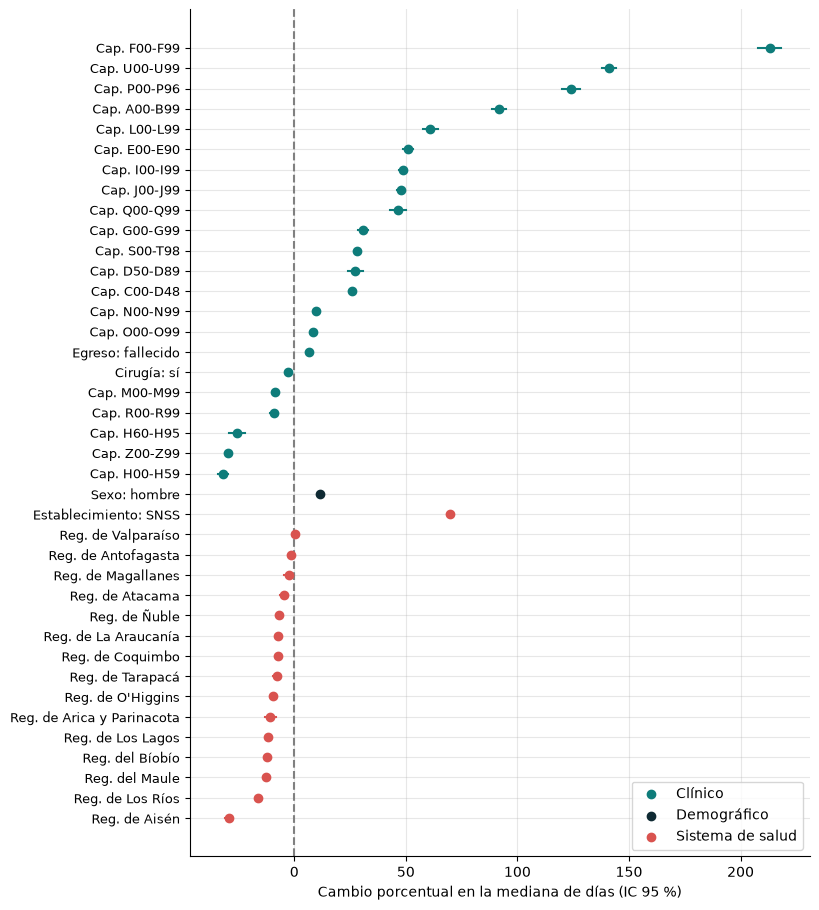

In [18]:
dibujo = coef.drop(["Intercept", "edad_c", "I(edad_c ** 2)"]).copy()
dibujo["bloque"] = np.where(dibujo.index.str.startswith(("capitulo", "cirugia", "fallecido")), "Clínico",
                    np.where(dibujo.index.str.startswith("sexo"), "Demográfico", "Sistema de salud"))
colores = {"Clínico": teal, "Demográfico": petroleo, "Sistema de salud": coral}
dibujo = dibujo.sort_values(["bloque", "%Δ"], ascending=[False, True])

fig, ax = plt.subplots(figsize=(8, 11))
for y, (nombre, fila) in enumerate(dibujo.iterrows()):
    ax.plot([fila["%Δ inf"], fila["%Δ sup"]], [y, y], color=colores[fila["bloque"]])
    ax.scatter(fila["%Δ"], y, color=colores[fila["bloque"]], zorder=3)
ax.axvline(0, color="gray", linestyle="--")
etiquetas = (dibujo.index
    .str.replace("capitulo: ", "Cap. ", regex=False)
    .str.replace("region: De Aisén del Gral. C. Ibáñez del Campo", "Reg. de Aisén", regex=False)
    .str.replace("region: De Magallanes y de La Antártica Chilena", "Reg. de Magallanes", regex=False)
    .str.replace("region: Del Libertador B. O'Higgins", "Reg. de O'Higgins", regex=False)
    .str.replace("region: De La Araucanía", "Reg. de La Araucanía", regex=False)
    .str.replace("region: De ", "Reg. de ", regex=False)
    .str.replace("region: Del ", "Reg. del ", regex=False)
    .str.replace("establecimiento: SNSS", "Establecimiento: SNSS", regex=False)
    .str.replace("sexo: HOMBRE", "Sexo: hombre", regex=False)
    .str.replace("fallecido: Sí", "Egreso: fallecido", regex=False)
    .str.replace("cirugia: Sí", "Cirugía: sí", regex=False))
ax.set_yticks(range(len(dibujo)), etiquetas, fontsize=9)
ax.set_xlabel("Cambio porcentual en la mediana de días (IC 95 %)")
for bloque, c in colores.items():
    ax.scatter([], [], color=c, label=bloque)
ax.legend(loc="lower right")
fig.savefig("figures/avance2_forest.png", dpi=200, bbox_inches="tight")
plt.show()


Los intervalos casi no se ven, salvo en capítulos con pocos egresos. Dentro del bloque clínico, el capítulo tiene los %Δ más grandes; entre los demás, el establecimiento SNSS (+69,7 %) queda muy por encima de sexo, cirugía, condición de egreso y casi todas las regiones. Por η² parcial (3.2) el orden es capítulo (0,074, mediano), establecimiento (0,041) y edad (0,035), estos dos pequeños; los otros cuatro quedan bajo 0,01. Para planificar camas, diagnóstico, tipo de establecimiento y edad son lo más asociado a cuántos días ocupa un egreso.

**Figura 6.** Media observada de ln(días) por tramo de edad (línea verde azulado) y media predicha por M3 en los mismos egresos (línea coral), en los datos de entrenamiento.

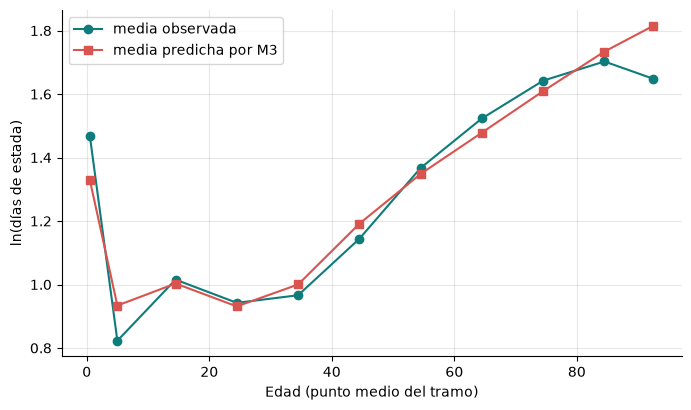

edad      0.5   5.0   14.5  24.5  34.5  44.5  54.5  64.5  74.5  84.5  92.5
log_dias  1.47  0.82  1.02  0.94  0.97  1.14  1.37  1.52  1.64  1.70  1.65
pred      1.33  0.93  1.00  0.93  1.00  1.19  1.35  1.48  1.61  1.73  1.82


In [19]:
train["pred"] = m3.fittedvalues
por_tramo = train.groupby("edad")[["log_dias", "pred"]].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(por_tramo.index, por_tramo["log_dias"], marker="o", color=teal, label="media observada")
ax.plot(por_tramo.index, por_tramo["pred"], marker="s", color=coral, label="media predicha por M3")
ax.set_xlabel("Edad (punto medio del tramo)")
ax.set_ylabel("ln(días de estada)")
ax.legend()
fig.savefig("figures/avance2_edad.png", dpi=200, bbox_inches="tight")
plt.show()
print(por_tramo.round(2).T.to_string())


El modelo sigue la subida desde los 20 años (0,93 a 1,82 en la predicción; 0,94 a 1,65 en lo observado, entre 24,5 y 92,5 años). Falla en los extremos: en menores de un año predice 1,33 y lo observado es 1,47; entre 1 y 9 años, 0,93 contra 0,82, y entre 1 y 39 años el promedio observado va de 0,82 a 1,02. Sobre los 80 años lo observado se aplana (1,70 entre 80 y 89, 1,65 en el total) y el modelo sigue subiendo (1,73 y 1,82). Incluimos edad² porque en el Avance 1 la edad tenía forma de U (15,4 % de prolongadas en menores de un año, 3,5 % entre 20 y 29, 15,4 % entre 70 y 79; mediana de 4 días en menores de un año y 2 en adultos jóvenes), pero el término estimado es casi 0 (edad² ≈ 0) y la curva queda casi recta. Otra posible explicación, no probada: el capítulo P00-P96 absorbe el alza de los lactantes. Queda como limitación.

### 3.4 Evaluación en el conjunto de test

Predecimos el 30 % de test con los coeficientes de entrenamiento. Como el modelo está en logaritmo, exp(ŷ) estima la mediana de los días. Por eso en días medimos el error absoluto medio (MAE), que se minimiza con la mediana, y lo comparamos con una línea base que predice siempre la mediana de entrenamiento. En ln(días) informamos también el R² ajustado y el RMSE, contra una línea base que predice la media.

**Tabla 11.** Métricas de M3 en entrenamiento, test y línea base. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [20]:
test["pred"] = m3.predict(test)
k = int(m3.df_model) + 1
for d in (train, test):
    d["pred_dias"] = np.exp(d["pred"])              # estima la mediana de los días

filas = []
for nombre, d in [("train", train), ("test", test)]:
    e, ed = d["log_dias"] - d["pred"], d["dias_estada"] - d["pred_dias"]
    r2 = 1 - (e ** 2).sum() / ((d["log_dias"] - d["log_dias"].mean()) ** 2).sum()
    filas.append({"conjunto": nombre, "R²": r2, "R² aj.": 1 - (1 - r2) * (len(d) - 1) / (len(d) - k),
                  "MAE ln": e.abs().mean(), "RMSE ln": np.sqrt((e ** 2).mean()),
                  "MAE días": ed.abs().mean()})
filas.append({"conjunto": "línea base en test",
              "MAE ln": (test["log_dias"] - train["log_dias"].median()).abs().mean(),        # la mediana minimiza el MAE
              "RMSE ln": np.sqrt(((test["log_dias"] - train["log_dias"].mean()) ** 2).mean()),  # la media minimiza el RMSE
              "MAE días": (test["dias_estada"] - train["dias_estada"].median()).abs().mean()})
metricas = pd.DataFrame(filas).set_index("conjunto")
print("Mediana de train:", train["dias_estada"].median(), "días | mediana del perfil de referencia, exp(β0):", round(np.exp(coef.loc["Intercept", "β"]), 2), "días")
metricas.round(3)


Mediana de train: 3.0 días | mediana del perfil de referencia, exp(β0): 1.82 días


,R²,R² aj.,MAE ln,RMSE ln,MAE días
conjunto,,,,,
train,0.198,0.198,0.727,0.927,4.683
test,0.198,0.198,0.727,0.927,4.669
línea base en test,NaN,NaN,0.828,1.035,5.025


En ln(días) el modelo mejora a la línea base: R² ajustado 0,198 en test, MAE 0,727 contra 0,828 y RMSE 0,927 contra 1,035. Entrenamiento y test dan lo mismo (R² ajustado 0,198 en ambos; RMSE en ln de 0,927), así que no hay sobreajuste.

En días, el MAE en test es 4,67 contra 5,03 de predecir siempre la mediana (3 días): un 7 % menos.

El R² de 0,198 es un η² grande según Cohen (1988). Aun así, un error de casi 5 días sobre una mediana de 3 muestra que buena parte de la duración no se explica con estos 7 factores.

### 3.5 Calibración

Juntamos los egresos de test en diez grupos según la duración predicha y comparamos, en cada uno, la media geométrica de los días predichos y observados (la media geométrica es lo que modela el ln(días)):

**Tabla 12.** Días predichos y observados por decil de la predicción, en test. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [21]:
test["decil"] = pd.qcut(test["pred_dias"].rank(method="first"), 10, labels=False) + 1
gm = lambda s: np.exp(np.log(s).mean())            # media geométrica de los días
cal = pd.DataFrame({"egresos": test.groupby("decil").size(),
                    "predicha (media geométrica)": test.groupby("decil")["pred_dias"].apply(gm),
                    "observada (media geométrica)": test.groupby("decil")["dias_estada"].apply(gm),
                    "observada (mediana)": test.groupby("decil")["dias_estada"].median()})
cal.round(2)

,egresos,predicha (media geométrica),observada (media geométrica),observada (mediana)
decil,,,,
1,29043,1.60,1.66,2.0
2,29043,2.21,2.14,2.0
3,29043,2.59,2.51,2.0
4,29043,2.82,2.61,2.0
5,29043,3.11,2.96,3.0
6,29042,3.57,3.66,3.0
7,29043,4.19,4.55,4.0
8,29043,4.88,5.26,5.0
9,29043,5.75,5.95,6.0


Los puntos quedan cerca de la diagonal: el modelo ordena bien los egresos por duración. Los desvíos son pequeños. Del decil 2 al 5 predice algo más de lo observado (2,59 contra 2,51 días en el decil 3), del 6 al 9 algo menos (4,19 contra 4,55 en el 7) y en el último más (8,07 contra 7,39). Sirve para distinguir grupos de egresos, no para predecir un egreso puntual.

**Figura 7.** Calibración en test: media geométrica de los días predichos y observados en cada decil de la predicción.

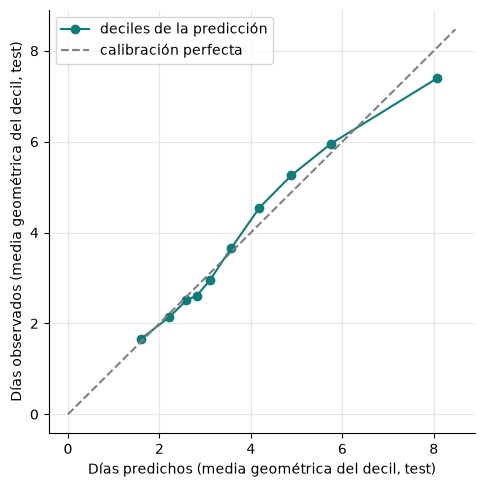

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(cal["predicha (media geométrica)"], cal["observada (media geométrica)"], marker="o", color=teal, label="deciles de la predicción")
lim = [0, cal[["predicha (media geométrica)", "observada (media geométrica)"]].max().max() * 1.05]
ax.plot(lim, lim, color="gray", linestyle="--", label="calibración perfecta")
ax.set_xlabel("Días predichos (media geométrica del decil, test)")
ax.set_ylabel("Días observados (media geométrica del decil, test)")
ax.legend()
fig.savefig("figures/avance2_calibracion.png", dpi=200, bbox_inches="tight")
plt.show()

Los puntos siguen la diagonal: el modelo ordena bien los egresos por duración. Hay desvíos: en el decil más bajo predice 2,69 días y lo observado es 2,15 (sobreestima). En los deciles 6 al 9 (contando desde 1) predice menos de lo observado, por ejemplo 7,02 contra 8,18 y 8,18 contra 9,55. El último queda bien (13,76 contra 13,51). Sirve para distinguir grupos de egresos, no para predecir un egreso puntual.

### 3.6 Supuestos del modelo

Revisamos los supuestos del estimador de mínimos cuadrados ordinarios (EMCO) del curso (Rodríguez y González, 2017). Los cinco primeros dan un estimador lineal, insesgado y de mínima varianza (Gauss-Markov). El sexto, normalidad, solo sirve para inferencia exacta con muestras pequeñas.

| Supuesto | Qué revisamos |
|---|---|
| 1. Linealidad | Residuos contra valores ajustados (figura 8) |
| 2. Rango completo de X (sin multicolinealidad) | Rango de la matriz de diseño y VIF |
| 3. Esperanza condicional nula | No se verifica (propiedad del EMCO según el material del curso). Con intercepto, la media de los residuos es 0 por construcción |
| 4. Perturbaciones esféricas (varianza constante y sin autocorrelación) | Desviación de los residuos por cuartil de valores ajustados (figura 8); independencia, discutida más abajo |
| 5. Variables explicativas no aleatorias | No se verifica con los datos |
| 6. Normalidad de los errores | Histograma y Q-Q de los residuos (figura 8) |

El VIF lo calculamos sobre 30.000 egresos de entrenamiento al azar, porque con los 677.669 son muy lentos.

In [23]:
X, r = m3.model.exog, m3.resid.values
pos = np.random.default_rng(1).choice(len(r), 30000, replace=False)     # muestra de 30.000 para el VIF
print("Rango de X:", np.linalg.matrix_rank(X), "de", X.shape[1], "columnas")
vif = pd.Series([variance_inflation_factor(X[pos], i) for i in range(1, X.shape[1])], index=m3.model.exog_names[1:])
print("VIF máximo:", round(vif.max(), 2), "en", vif.idxmax())
print("Media de los residuos:", round(r.mean(), 6))
cuartil = pd.qcut(m3.fittedvalues.rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("Desviación estándar de los residuos por cuartil de ajustados:", m3.resid.groupby(cuartil, observed=True).std().round(3).to_dict())
print("Asimetría de los residuos:", round(stats.skew(r), 3), "| curtosis en exceso:", round(stats.kurtosis(r), 3))


Rango de X: 42 de 42 columnas


VIF máximo: 2.39 en C(capitulo, Treatment('K00-K93'))[T.O00-O99]
Media de los residuos: 0.0
Desviación estándar de los residuos por cuartil de ajustados: {'Q1': 0.713, 'Q2': 0.848, 'Q3': 1.038, 'Q4': 1.061}
Asimetría de los residuos: 0.493 | curtosis en exceso: 0.544


- Rango completo: rango 42, igual al número de columnas. VIF máximo 2,39 (bajo 10), así que no hay multicolinealidad.
- Esperanza condicional nula: es propiedad del EMCO según el material del curso, no algo que verifiquemos. Que la media de los residuos dé 0 es identidad del ajuste con intercepto.
- Varianza constante: la desviación estándar de los residuos sube de 0,713 a 1,061 entre cuartiles de valores ajustados (figura 8), así que no se cumple. Los coeficientes siguen insesgados, pero los errores estándar clásicos no son confiables: valores-p e intervalos son aproximados. Por eso la relevancia la decidimos con η², que sale de los R² y no de los errores estándar.
- Independencia: no usamos Durbin-Watson, porque la base no trae fechas. La limitación real es que la unidad es el egreso, no el paciente, y los reingresos no son independientes. Los errores son algo optimistas.
- Explicativas no aleatorias: se asume, y el modelo es condicional a sus valores.
- Normalidad: asimetría 0,493 y curtosis en exceso 0,544.

**Figura 8.** Residuos contra valores ajustados de ln(días) (izquierda), histograma de los residuos (centro) y gráfico Q-Q (derecha).

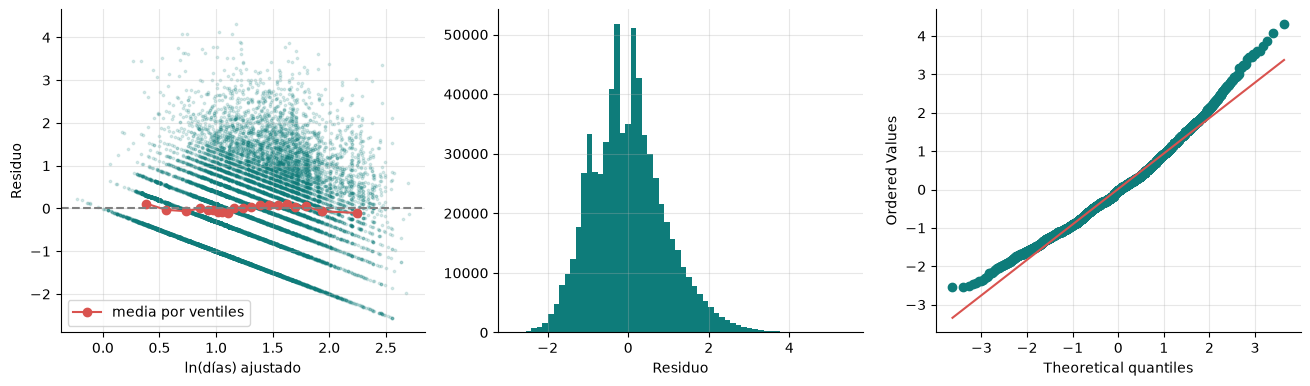

In [24]:
dec = pd.qcut(m3.fittedvalues.rank(method="first"), 20, labels=False)
medias = pd.DataFrame({"ajustado": m3.fittedvalues, "residuo": m3.resid}).groupby(dec).mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(m3.fittedvalues.values[pos[:20000]], r[pos[:20000]], s=3, alpha=0.15, color=teal)
ax[0].plot(medias["ajustado"], medias["residuo"], color=coral, marker="o", label="media por ventiles")
ax[0].axhline(0, color="gray", linestyle="--")
ax[0].set_xlabel("ln(días) ajustado")
ax[0].set_ylabel("Residuo")
ax[0].legend()
ax[1].hist(r, bins=60, color=teal)
ax[1].set_xlabel("Residuo")
stats.probplot(r[pos[:5000]], plot=ax[2])
ax[2].set_title("")
ax[2].get_lines()[0].set_color(teal)
ax[2].get_lines()[1].set_color(coral)
fig.savefig("figures/avance2_residuos.png", dpi=200, bbox_inches="tight")
plt.show()


A la izquierda, la media de los residuos (línea roja) queda cerca de 0, así que la linealidad es razonable. Las diagonales vienen de los días enteros. La nube se abre hacia arriba a la derecha, es decir, heterocedasticidad. El histograma tiene cola derecha y el Q-Q se separa en los extremos. Con 677.669 egresos, la inferencia se apoya en el teorema central del límite, y Gauss-Markov no necesita normalidad.

### 3.7 Avance 1 contra Avance 2

La tabla compara cada factor en el Avance 1 (de a pares) y en el modelo conjunto M3.

**Tabla 13.** Avance 1 contra Avance 2. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [25]:
d74 = 74.5 - edad_prom
pct_edad = 100 * (np.exp(coef.loc["edad_c", "β"] * d74 + coef.loc["I(edad_c ** 2)", "β"] * d74 ** 2) - 1)
pct_cap = coef.loc[en_cap, "%Δ"]
w_cap, w_reg = ftest.loc["capitulo"], ftest.loc["region"]
print("Edad a los 74,5 años frente a la edad media: %Δ =", round(pct_edad, 1), "%")
def es(x, d=1, signo=False):                      # número con coma decimal y punto de miles
    return f"{x:{'+' if signo else ''},.{d}f}".translate(str.maketrans(",.-", ".,−"))
fmt = lambda nombre: f"{es(coef.loc[nombre, '%Δ'], 1, True)} % [{es(coef.loc[nombre, '%Δ inf'], 1, True)}; {es(coef.loc[nombre, '%Δ sup'], 1, True)}]"
filas = [
    ("Establecimiento (SNSS)", "r = −0,37: el SNSS tiene más días", fmt("establecimiento: SNSS"), "Sigue asociado con más días después de controlar por diagnóstico, edad y región; relevante"),
    ("Capítulo CIE-10", "ε² = 0,12; V = 0,25", f"F = {es(w_cap['F'], 0)} (gl = {w_cap['gl']:.0f}); %Δ de {es(pct_cap.min(), 1, True)} a {es(pct_cap.max(), 1, True)} % vs. K00-K93", "Sigue siendo el factor con mayor η²; relevante"),
    ("Sexo (hombre vs. mujer)", "r = 0,14: los hombres tienen más días", fmt("sexo: HOMBRE"), "Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el η² queda bajo 0,01: significativo, no relevante"),
    ("Edad", "ρ = 0,25: a más edad, más días", f"{es(pct_edad, 1, True)} % a los 74,5 años vs. la edad media", "Sigue subiendo con la edad, con la curva ajustada casi recta; relevante. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida"),
    ("Cirugía (sí)", "r = 0,22: los no operados tienen más días (mediana 4 contra 2)", fmt("cirugia: Sí"), "Misma dirección (los operados tienen menos días que los no operados), pero el η² queda bajo 0,01: no relevante. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43)"),
    ("Fallecido (sí)", "r = −0,29: los fallecidos tienen más días", fmt("fallecido: Sí"), "De a pares tenía más días; con el resto controlado el η² queda bajo 0,01: no relevante. Posiblemente buena parte se asocia con diagnóstico y edad"),
    ("Región", "ε² = 0,002", f"F = {es(w_reg['F'], 1)} (gl = {w_reg['gl']:.0f}); %Δ de {es(coef.loc[en_reg, '%Δ'].min(), 1, True)} a {es(coef.loc[en_reg, '%Δ'].max(), 1, True)} % vs. Santiago", "De a pares casi no se veía y al controlar el η² sigue bajo 0,01: significativa como conjunto, no relevante. Aisén es la más baja"),
]
e2p = {"Establecimiento (SNSS)": "establecimiento", "Capítulo CIE-10": "capítulo", "Sexo (hombre vs. mujer)": "sexo", "Edad": "edad (edad y edad²)",
       "Cirugía (sí)": "cirugía", "Fallecido (sí)": "fallecido", "Región": "región"}
e2txt = lambda nombre: f"{es(parciales.loc[e2p[nombre], 'η² parcial'], 4)} ({parciales.loc[e2p[nombre], 'efecto (Cohen)']})"
tabla = "| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la mediana [IC 95 %]) | η² parcial (Cohen) | Qué cambia |\n|---|---|---|---|---|\n"
tabla += "\n".join(f"| {a} | {b} | {c} | {e2txt(a)} | {d} |" for a, b, c, d in filas)
display(Markdown(tabla))


Edad a los 74,5 años frente a la edad media: %Δ = 31.5 %


| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la mediana [IC 95 %]) | η² parcial (Cohen) | Qué cambia |
|---|---|---|---|---|
| Establecimiento (SNSS) | r = −0,37: el SNSS tiene más días | +69,7 % [+68,6; +70,7] | 0,0407 (pequeño) | Sigue asociado con más días después de controlar por diagnóstico, edad y región; relevante |
| Capítulo CIE-10 | ε² = 0,12; V = 0,25 | F = 2.704 (gl = 20); %Δ de −32,1 a +213,0 % vs. K00-K93 | 0,0739 (mediano) | Sigue siendo el factor con mayor η²; relevante |
| Sexo (hombre vs. mujer) | r = 0,14: los hombres tienen más días | +11,4 % [+10,8; +11,9] | 0,0026 (menor que pequeño) | Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el η² queda bajo 0,01: significativo, no relevante |
| Edad | ρ = 0,25: a más edad, más días | +31,5 % a los 74,5 años vs. la edad media | 0,0352 (pequeño) | Sigue subiendo con la edad, con la curva ajustada casi recta; relevante. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida |
| Cirugía (sí) | r = 0,22: los no operados tienen más días (mediana 4 contra 2) | −2,7 % [−3,2; −2,2] | 0,0002 (menor que pequeño) | Misma dirección (los operados tienen menos días que los no operados), pero el η² queda bajo 0,01: no relevante. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43) |
| Fallecido (sí) | r = −0,29: los fallecidos tienen más días | +6,5 % [+5,2; +7,7] | 0,0002 (menor que pequeño) | De a pares tenía más días; con el resto controlado el η² queda bajo 0,01: no relevante. Posiblemente buena parte se asocia con diagnóstico y edad |
| Región | ε² = 0,002 | F = 215,5 (gl = 15); %Δ de −29,5 a +0,2 % vs. Santiago | 0,0047 (menor que pequeño) | De a pares casi no se veía y al controlar el η² sigue bajo 0,01: significativa como conjunto, no relevante. Aisén es la más baja |

Las cifras de los dos avances no son comparables en magnitud: el Avance 1 es de a pares y el Avance 2 controla por los otros factores. Sí lo son en dirección y en orden de factores. La edad, por ejemplo, tiene ρ = 0,25 de a pares y +31,5 % a los 74,5 años ajustado. Con el signo, en el Avance 1 depende del orden de los grupos. En cirugía, r = +0,22 significa que los no operados tienen más días, y el −2,7 % del modelo (operados con menos días) va en la misma dirección. Cirugía y condición de egreso se achican en el modelo conjunto, probablemente porque comparten información con el capítulo (no lo probamos). La región sigue bajo el umbral de pequeño (η² parcial 0,0047).


### 3.8 Mejora del modelo para predecir

M3 es el modelo del Avance 1 y lo mantenemos para interpretar los coeficientes. Pero predice poco (R² ajustado de 0,198), y los resultados anteriores muestran dos carencias concretas. Decidimos corregir cada una:

- La edad: El término edad² salió casi 0, y la curva ajustada no capta el alza de los menores de un año ni la meseta sobre los 80 (figura 6). Reemplazamos edad y edad² por los 11 tramos de edad como categorías (M4), con 40 a 49 años de referencia, el tramo más cercano a la edad media. M3 queda anidado en M4, porque la edad solo toma esos 11 valores.
- Efectos que dependen del diagnóstico y de la edad: El +69,7 % del SNSS es un promedio, y puede cambiar según el capítulo o el tramo de edad. Agregamos la interacción capítulo × establecimiento (M5) y tramo de edad × establecimiento (M6), como las interacciones A×B del ANOVA de dos factores.

Juzgamos cada paso con el criterio del Avance 1, fijado antes de ver los resultados: BIC para elegir, F parcial para el aporte de cada bloque y η² parcial (Cohen, 1988) para su tamaño. Para decidir qué factores interpretar exigimos η² ≥ 0,01. Para predecir pedimos que el BIC baje y que el error en test no empeore. Ajustamos en entrenamiento y evaluamos en test una sola vez.

**Tabla 14.** Modelos M3 a M6 en entrenamiento. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [26]:
tr = "C(tramo_edad, Treatment('40 a 49'))"
f4 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido) + {tr} + C(sexo, Treatment('MUJER')) + C(establecimiento) + {reg}"
f5 = f4 + f" + {cap}:C(establecimiento)"           # M5: capítulo × establecimiento
f6 = f5 + f" + {tr}:C(establecimiento)"             # M6: tramo de edad × establecimiento
cand = [m3] + [smf.ols(f, train).fit() for f in (f4, f5, f6)]
nombres = ["M3", "M4", "M5", "M6"]

filas = []
for i, (n, m) in enumerate(zip(nombres, cand)):
    fila = {"modelo": n, "k": int(m.df_model) + 1, "R² aj.": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic}
    if i > 0:
        a = anova_lm(cand[i - 1], m)
        fila.update({"Δ BIC": m.bic - cand[i - 1].bic, "F parcial": a["F"].iloc[1], "gl": int(a["df_diff"].iloc[1]),
                     "valor-p": a["Pr(>F)"].iloc[1], "η² parcial": (m.rsquared - cand[i - 1].rsquared) / (1 - cand[i - 1].rsquared)})
    filas.append(fila)
tabla_mejoras = pd.DataFrame(filas).set_index("modelo")
tabla_mejoras.round(4)

,k,R² aj.,AIC,BIC,Δ BIC,F parcial,gl,valor-p,η² parcial
modelo,,,,,,,,,
M3,42,0.1981,1.820447e+06,1.820927e+06,NaN,NaN,NaN,NaN,NaN
M4,50,0.2020,1.817133e+06,1.817704e+06,-3223.0358,417.2998,8.0,0.0,0.0049
M5,70,0.2142,1.806766e+06,1.807566e+06,-10138.0800,524.2920,20.0,0.0,0.0152
M6,80,0.2148,1.806205e+06,1.807119e+06,-447.4109,58.1856,10.0,0.0,0.0009


El BIC baja en los tres pasos (−3.223, −10.138 y −447) y los F parciales dan p < 0,001, así que elegimos M6 por BIC. El tamaño de la mejora cambia según el paso: el R² ajustado sube de 0,198 (M3) a 0,202 (M4), 0,214 (M5) y 0,215 (M6), con η² parcial de 0,0049, 0,0152 y 0,0009. Solo la interacción capítulo × establecimiento (M5) pasa el umbral de 0,01, y es la que más aporta (+0,012 de R² ajustado). Los tramos de edad (M4) y la interacción tramo de edad × establecimiento (M6) casi no agregan (+0,0006 el último), y el BIC los prefiere por el tamaño de la muestra.

**Tabla 15.** Métricas de M3 a M6 en test. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [27]:
def evalua(m, d):
    p = m.predict(d)
    e, pdias = d["log_dias"] - p, np.exp(p)               # exp(ŷ) estima la mediana de los días
    r2 = 1 - (e ** 2).sum() / ((d["log_dias"] - d["log_dias"].mean()) ** 2).sum()
    k = int(m.df_model) + 1
    return {"R² aj.": 1 - (1 - r2) * (len(d) - 1) / (len(d) - k), "MAE ln": e.abs().mean(), "RMSE ln": np.sqrt((e ** 2).mean()),
            "MAE días": (d["dias_estada"] - pdias).abs().mean()}

test_mejoras = pd.DataFrame({n: evalua(m, test) for n, m in zip(nombres, cand)}).T
mejor = nombres[int(np.argmin([m.bic for m in cand]))]
print("Modelo elegido por BIC:", mejor)
test_mejoras.round(3)

Modelo elegido por BIC: M6


,R² aj.,MAE ln,RMSE ln,MAE días
M3,0.198,0.727,0.927,4.669
M4,0.201,0.725,0.925,4.662
M5,0.213,0.709,0.918,4.630
M6,0.214,0.709,0.918,4.629


En test, M6 mejora poco: el MAE en días baja de 4,67 a 4,63 y el R² ajustado sube de 0,198 a 0,214. Usamos M6 para predecir y M3 para interpretar los coeficientes. Corregir la forma funcional sube poco el R². Quizá falta información que la base no trae (gravedad, peso GRD, comorbilidades); no lo probamos. Con estas variables el modelo ordena bien a los grupos de egresos (figura 7), pero no acota la duración de un egreso: el MAE es de unos 4,6 días sobre una mediana de 3.

**Revisión de la selección de variables.** El BIC del Avance 1 eligió las 7 variables con los 968.098 egresos, antes de separar entrenamiento y test, así que el test no es del todo independiente de esa elección. Para revisarlo repetimos la comparación solo con entrenamiento: agregamos nacionalidad y etnia (las dos que el BIC dejó fuera) a M3.

**Tabla 16.** M3 contra M3 más nacionalidad y etnia, solo con datos de entrenamiento. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [29]:
m3x = smf.ols(f3 + " + C(nacionalidad) + C(etnia)", train).fit()
a = anova_lm(m3, m3x)
fuga = pd.DataFrame({"k": [int(m3.df_model) + 1, int(m3x.df_model) + 1], "R² aj.": [m3.rsquared_adj, m3x.rsquared_adj],
                     "BIC": [m3.bic, m3x.bic]}, index=["M3", "M3 + nacionalidad + etnia"])
fuga["F parcial"] = [np.nan, a["F"].iloc[1]]
fuga["valor-p"] = [np.nan, a["Pr(>F)"].iloc[1]]
fuga["η² parcial"] = [np.nan, (m3x.rsquared - m3.rsquared) / (1 - m3.rsquared)]
fuga.round(5)

,k,R² aj.,BIC,F parcial,valor-p,η² parcial
M3,42,0.19809,1.820927e+06,NaN,NaN,NaN
M3 + nacionalidad + etnia,44,0.19811,1.820936e+06,9.32588,0.00009,0.00003


El BIC sube en 8 (empeora), el R² ajustado no cambia (0,198) y el η² parcial es 0,00003. El F parcial sale significativo (p < 0,001) solo por el tamaño de la muestra. Con solo entrenamiento se toma la misma decisión que en el Avance 1: nacionalidad y etnia quedan fuera, y el test no se contamina por la selección.

### 3.9 Estadía prolongada: regresión logística

La pregunta tiene dos partes, y hasta aquí solo respondimos la duración. Para la estadía prolongada (más de 15 días, el percentil 90) el Avance 1 solo tuvo asociaciones de a pares (chi-cuadrado y V de Cramér), que no controlan por los demás factores. Ampliamos el análisis con la regresión logística, que vimos en el curso, porque la respuesta es Sí/No. Usamos los mismos 7 factores, con la edad en tramos como en M4, la misma partición 70/30 y el mismo criterio de comparación por bloques (razón de verosimilitud y BIC).

**Tabla 17.** Modelos logísticos anidados (entrenamiento). L1: bloque clínico; L2: más edad y sexo; L3: más establecimiento y región. D² de McFadden = 1 − devianza / devianza del modelo nulo. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [30]:
from scipy.stats import rankdata

for d in (train, test):
    d["y"] = (d["dias_estada"] > 15).astype(int)      # estadía prolongada: más de 15 días

sx = "C(sexo, Treatment('MUJER'))"
partes = {"capítulo": cap, "cirugía": "C(cirugia)", "fallecido": "C(fallecido)", "edad (tramos)": tr, "sexo": sx,
          "establecimiento": "C(establecimiento)", "región": reg}
def formula(sin=None):
    return "y ~ " + " + ".join(t for n, t in partes.items() if n != sin)

bloques_l = [("L0", "y ~ 1"), ("L1", "y ~ " + " + ".join([cap, "C(cirugia)", "C(fallecido)"])),
             ("L2", "y ~ " + " + ".join([cap, "C(cirugia)", "C(fallecido)", tr, sx])), ("L3", formula())]
ajustes = [smf.logit(f, train).fit(disp=0) for _, f in bloques_l]
filas = []
for i, ((n, _), m) in enumerate(zip(bloques_l, ajustes)):
    fila = {"modelo": n, "k": int(m.df_model) + 1, "devianza": -2 * m.llf, "AIC": m.aic, "BIC": m.bic, "D² McFadden": m.prsquared}
    if i > 0:
        lr = 2 * (m.llf - ajustes[i - 1].llf)
        gl = int(m.df_model - ajustes[i - 1].df_model)
        fila.update({"χ² (RV)": lr, "gl": gl, "valor-p": stats.chi2.sf(lr, gl), "Δ BIC": m.bic - ajustes[i - 1].bic})
    filas.append(fila)
tabla_logit = pd.DataFrame(filas).set_index("modelo")
tabla_logit.round(4)

,k,devianza,AIC,BIC,D² McFadden,χ² (RV),gl,valor-p,Δ BIC
modelo,,,,,,,,,
L0,1,422431.2353,422433.2353,422444.6617,0.0000,NaN,NaN,NaN,NaN
L1,23,377813.0642,377859.0642,378121.8718,0.1056,44618.1711,22.0,0.0,-44322.7899
L2,34,371562.1896,371630.1896,372018.6877,0.1204,6250.8746,11.0,0.0,-6103.1841
L3,50,366048.2686,366148.2686,366719.5893,0.1335,5513.9210,16.0,0.0,-5299.0984


Cada bloque mejora el ajuste: la razón de verosimilitud da p < 0,001 y el BIC baja en 44.323, 6.103 y 5.299. El D² de McFadden llega a 0,1335, un ajuste razonable.

Evaluamos L3 en test con la curva ROC y el AUC. Elegimos el umbral de clasificación con el índice de Youden (sensibilidad + especificidad − 1) calculado solo en entrenamiento, y medimos qué factor aporta sacándolo y viendo cuánto cae el D² de McFadden.

**Tabla 18.** Razón de verosimilitud y caída del D² de McFadden al sacar cada factor de L3 (entrenamiento). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [31]:
def auc(y, p):                                          # AUC por la suma de rangos (Mann-Whitney)
    r = rankdata(p)
    n1 = y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y) - n1))

l3 = ajustes[3]
p_tr, p_te = l3.predict(train), l3.predict(test)
auc_te, auc_tr = auc(test["y"].values, p_te.values), auc(train["y"].values, p_tr.values)

filas = []
for n in partes:                                        # sacamos un factor a la vez
    m = smf.logit(formula(n), train).fit(disp=0)
    lr = 2 * (l3.llf - m.llf)
    gl = int(l3.df_model - m.df_model)
    filas.append({"factor": n, "χ² (RV)": lr, "gl": gl, "valor-p": stats.chi2.sf(lr, gl),
                  "caída del D² de McFadden": l3.prsquared - m.prsquared})
delta_d2 = pd.DataFrame(filas).set_index("factor").sort_values("χ² (RV)", ascending=False)
print("AUC en test:", round(auc_te, 4), "| en entrenamiento:", round(auc_tr, 4), "| prevalencia en test:", round(test["y"].mean(), 4))
delta_d2.round(4)

AUC en test: 0.7696 | en entrenamiento: 0.7693 | prevalencia en test: 0.0937


,χ² (RV),gl,valor-p,caída del D² de McFadden
factor,,,,
capítulo,24593.4836,20,0.0,0.0582
edad (tramos),5516.2330,10,0.0,0.0131
establecimiento,4168.6546,1,0.0,0.0099
región,2038.7872,15,0.0,0.0048
fallecido,1113.4533,1,0.0,0.0026
sexo,748.6874,1,0.0,0.0018
cirugía,721.9316,1,0.0,0.0017


El AUC en test es 0,770 (0,769 en entrenamiento), así que discrimina bien y no hay sobreajuste. El capítulo es el factor que más aporta (el D² cae 0,058 al sacarlo), seguido de la edad (0,013) y el establecimiento (0,010). Región (0,0048), condición de egreso (0,0026), sexo (0,0018) y cirugía (0,0017) aportan poco. Los siete factores tienen p < 0,001 en la razón de verosimilitud.

**Tabla 19.** Matriz de confusión en test, con el umbral de Youden (0,085). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [32]:
ts = np.arange(0.02, 0.6, 0.005)                        # umbral de Youden, elegido solo en entrenamiento
youden = [(p_tr[train["y"] == 1] >= t).mean() - (p_tr[train["y"] == 0] >= t).mean() for t in ts]
umbral = ts[int(np.argmax(youden))]
y_te, pred = test["y"].values, (p_te >= umbral).astype(int).values
tp, fp = ((pred == 1) & (y_te == 1)).sum(), ((pred == 1) & (y_te == 0)).sum()
fn, tn = ((pred == 0) & (y_te == 1)).sum(), ((pred == 0) & (y_te == 0)).sum()
sens, esp, vpp, exact = tp / (tp + fn), tn / (tn + fp), tp / (tp + fp), (tp + tn) / len(y_te)
conf = pd.DataFrame({"predicho: prolongada": [tp, fp], "predicho: no prolongada": [fn, tn]}, index=["real: prolongada", "real: no prolongada"])
print(f"umbral = {umbral:.3f} | sensibilidad = {sens:.3f} | especificidad = {esp:.3f} | VPP = {vpp:.3f} | exactitud = {exact:.3f} | exactitud de decir siempre 'no' = {1 - y_te.mean():.3f}")
conf

umbral = 0.085 | sensibilidad = 0.804 | especificidad = 0.595 | VPP = 0.170 | exactitud = 0.614 | exactitud de decir siempre 'no' = 0.906


,predicho: prolongada,predicho: no prolongada
real: prolongada,21877,5336
real: no prolongada,106695,156521


Con ese umbral la sensibilidad es 0,804 y la especificidad 0,595, pero el valor predictivo positivo es solo 0,170: de cada 100 egresos que el modelo marca como prolongados, 17 lo son. La exactitud (0,614) es menor que la de decir siempre "no prolongada" (0,906), pero esa regla no detecta ninguna estadía prolongada, así que no usamos la exactitud para juzgar. Como la prevalencia es de solo 9,4 %, un VPP bajo es esperable.

Los cocientes de odds (OR) dan el tamaño de cada factor: un OR de 2 significa el doble de odds de una estadía prolongada que la categoría de referencia. En la logística no usamos escala de Cohen; miramos el OR con su IC y la caída del D² de la tabla 18.

**Tabla 20.** Cocientes de odds de L3 con IC de 95 % (Wald). Se muestran los factores binarios, los capítulos extremos y los tramos de edad. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [33]:
ic = l3.conf_int()
orr = pd.DataFrame({"OR": np.exp(l3.params), "IC inf": np.exp(ic[0]), "IC sup": np.exp(ic[1]), "valor-p": l3.pvalues})
orr.index = orr.index.str.replace(r"C\((\w+)[^\[]*\[T\.(.*)\]", r"\1: \2", regex=True)
en_capl = orr.index[orr.index.str.startswith("capitulo")]
extremos = list(orr.loc[en_capl, "OR"].nlargest(3).index) + list(orr.loc[en_capl, "OR"].nsmallest(1).index)
tramos = list(orr.index[orr.index.str.startswith("tramo")])
orr.loc[["cirugia: Sí", "fallecido: Sí", "sexo: HOMBRE", "establecimiento: SNSS"] + extremos + tramos].round(3)

,OR,IC inf,IC sup,valor-p
cirugia: Sí,1.358,1.328,1.388,0.0
fallecido: Sí,1.763,1.707,1.821,0.0
sexo: HOMBRE,1.277,1.255,1.300,0.0
establecimiento: SNSS,2.548,2.470,2.628,0.0
capitulo: F00-F99,12.724,12.123,13.354,0.0
capitulo: U00-U99,4.528,4.345,4.719,0.0
capitulo: A00-B99,3.800,3.597,4.014,0.0
capitulo: O00-O99,0.263,0.246,0.281,0.0
tramo_edad: 1 a 9,0.436,0.410,0.465,0.0
tramo_edad: 10 a 19,0.693,0.658,0.730,0.0


El establecimiento SNSS tiene OR = 2,55 (IC 95 %: 2,47 a 2,63): con el diagnóstico, la edad y la región controlados, el SNSS tiene más del doble de odds de una estadía prolongada. En el Avance 1, de a pares, el establecimiento tenía V = 0,08 (despreciable). La dirección es la misma, pero al controlar por los demás factores el efecto crece. Quizá de a pares lo tapaba la composición de diagnósticos de cada tipo de establecimiento (no lo comprobamos). Fallecido (OR = 1,76) también pesa. Cirugía (OR = 1,36) y hombre (OR = 1,28) aportan poco, como en la duración. En cirugía la dirección es la contraria: los operados tienen una mediana de días 2,7 % menor (lineal) y a la vez más odds de pasar de 15 días. Quizá los operados duran menos en general y tienen una cola larga de complicaciones; no lo probamos. Entre los capítulos, F00-F99 tiene OR = 12,7 y O00-O99 tiene OR = 0,263 (menos odds que K00-K93). La edad vuelve a tener forma de U, como en el Avance 1: los tramos de 1 a 9 años tienen OR = 0,436 y los de 70 a 79 años, OR = 1,76.

**Figura 9.** Curva ROC en test (izquierda) y calibración por decil de la probabilidad predicha (derecha) del modelo logístico.

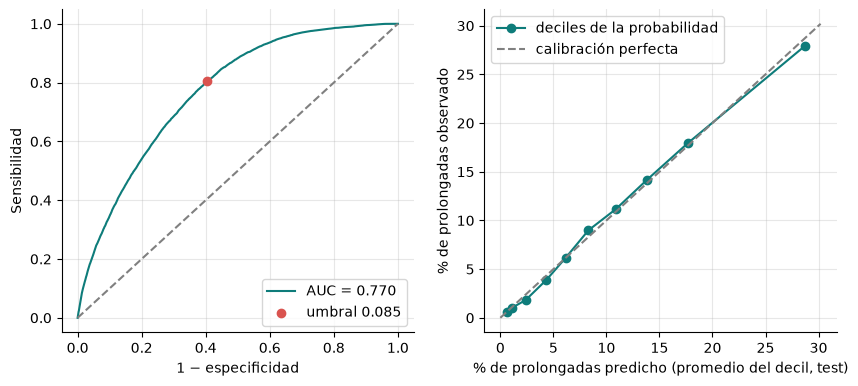

        0    1    2    3    4    5     6     7     8     9
pred  0.6  1.1  2.4  4.3  6.2  8.3  10.9  13.8  17.7  28.8
obs   0.6  1.0  1.8  3.9  6.2  9.0  11.2  14.2  17.9  28.0


In [34]:
o = np.argsort(-p_te.values)
yy = y_te[o]
tpr, fpr = np.cumsum(yy) / yy.sum(), np.cumsum(1 - yy) / (1 - yy).sum()
dec = pd.qcut(p_te.rank(method="first"), 10, labels=False)
cal_l = pd.DataFrame({"pred": p_te, "obs": test["y"]}).groupby(dec).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].plot(fpr[::200], tpr[::200], color=teal, label=f"AUC = {auc_te:.3f}")
ax[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
ax[0].scatter([1 - esp], [sens], color=coral, zorder=3, label=f"umbral {umbral:.3f}")
ax[0].set_xlabel("1 − especificidad")
ax[0].set_ylabel("Sensibilidad")
ax[0].legend(loc="lower right")
ax[1].plot(cal_l["pred"], cal_l["obs"], marker="o", color=teal, label="deciles de la probabilidad")
lim = [0, cal_l.max().max() * 1.05]
ax[1].plot(lim, lim, color="gray", linestyle="--", label="calibración perfecta")
ax[1].set_xlabel("% de prolongadas predicho (promedio del decil, test)")
ax[1].set_ylabel("% de prolongadas observado")
ax[1].legend(loc="upper left")
fig.savefig("figures/avance2_roc.png", dpi=200, bbox_inches="tight")
plt.show()
print(cal_l.round(1).T.to_string())

La curva se separa bien de la diagonal, y los puntos de calibración siguen la diagonal: en el decil más bajo el modelo predice 0,6 % de estadías prolongadas y se observa 0,6 %, y en el más alto predice 28,8 % y se observa 28,0 %. El modelo sirve para ordenar egresos por riesgo de estadía prolongada; con un VPP de 0,17, no sirve para etiquetar un egreso individual como prolongado.

## 4. Discusión y conclusiones

### 4.1 Hallazgos

1. Duración: el capítulo tiene el mayor η² parcial (0,074, mediano). La mediana cambia de −32 % a +213 % entre capítulos respecto de K00-K93.
2. Establecimiento: segundo factor (η² parcial 0,041, pequeño). La mediana en el SNSS es 69,7 % mayor, y en la estadía prolongada el OR es 2,55.
3. Edad: tercer factor (η² parcial 0,035, pequeño). La mediana sube 0,9 % por año. En la prolongada vuelve la U del Avance 1 (OR de 0,436 entre 1 y 9 años y de 1,76 entre 70 y 79).
4. Factores no relevantes: sexo (η² 0,0026), cirugía y condición de egreso (0,0002 cada una) y región (0,0047) son significativos pero no relevantes en la duración. En la prolongada, la condición de egreso pesa más (OR 1,76), y cirugía y sexo aportan poco (el D² cae 0,0017 y 0,0018).
5. Desempeño: M3 explica el 19,8 % de ln(días), igual en test. M6 sube el R² ajustado a 0,215 y baja el MAE en días de 4,67 a 4,63: poco. La logística tiene AUC de 0,770 en test, con VPP de 0,17.

### 4.2 Relación con las hipótesis

**Decisión (α = 0,05).** Rechazamos H₀ y se cumplen H1a, H1b y H1c para la duración (F global, F por factor y coeficientes con p < 0,001) y para la estadía prolongada (razón de verosimilitud con p < 0,001 en los siete factores). Con 968.098 egresos cualquier diferencia sale significativa, así que juzgamos la relevancia con el criterio del Avance 1: significativo y η² ≥ 0,01 (Cohen, 1988). En la logística ordenamos los factores por la caída del D² de McFadden. Lin et al. (2013) recomiendan reportar el tamaño del efecto junto al valor-p.

| Hipótesis | Duración (modelo lineal) | Prolongada (modelo logístico) | Lectura |
|---|---|---|---|
| H1a (clínicos) | Capítulo F = 2.704, η² parcial 0,074 (mediano). Cirugía y fallecido, 0,0002 c/u | Capítulo, el D² cae 0,058 (F00-F99: OR 12,7). Fallecido OR 1,76; cirugía OR 1,36 | Se cumple por el capítulo en las dos respuestas, y por la condición de egreso en la prolongada. Cirugía aporta poco |
| H1b (demográficos) | Edad +0,9 % por año, η² parcial 0,035 (pequeño). Hombre +11,4 %, η² 0,0026 | Edad, el D² cae 0,013 (OR hasta 1,76). Hombre OR 1,28 | Se cumple por la edad (en la prolongada, con forma de U). Sexo no es relevante. Nacionalidad y etnia quedaron fuera por el BIC, y lo confirmamos solo con entrenamiento (3.8) |
| H1c (sistema de salud) | SNSS +69,7 %, η² parcial 0,041 (pequeño). Región η² 0,0047 | SNSS OR 2,55 (el D² cae 0,0099). Región, el D² cae 0,0048 | Se cumple por el establecimiento. Región no es relevante |

### 4.3 Coherencia con la literatura

- El diagnóstico como factor principal coincide con la lógica de los GRD (Fetter et al., 1980).
- Establecimiento y edad, al controlar por diagnóstico, coinciden con Freitas et al. (2012), que los asocian con estadías extremas dentro de un mismo GRD, en Portugal.
- Olivares-Tirado (2020) también halló más estadías largas con la edad en Chile, aunque solo en adultos mayores. Nuestra logística muestra la misma tendencia sobre los 60 años, y además el alza en menores de un año.
- El BIC (Raftery, 1995) dejó 7 variables y descartó nacionalidad y etnia.

### 4.4 Posibles explicaciones

Los datos muestran asociaciones; no hay causas probadas. Posibles explicaciones que no probamos:

- El SNSS podría concentrar casos más graves o complejos, y la base no trae gravedad para separarlo. Eso también podría explicar por qué su efecto crece en la logística al controlar por diagnóstico.
- Los hombres podrían tener casos más graves o procedimientos distintos dentro de cada capítulo.
- El poco aumento del R² al mejorar la forma del modelo (M4 a M6) es consistente con que lo que falta explicar es gravedad.

### 4.5 Sesgos y limitaciones

- La unidad es el egreso, no el paciente. Los reingresos no son independientes, y los valores-p y los intervalos salen algo optimistas.
- La base no trae GRD, gravedad, comorbilidades, hospital ni fechas. El R² es bajo, y es posible que establecimiento o región recojan diferencias de gravedad.
- La selección de variables del Avance 1 usó todos los egresos. La repetimos solo con entrenamiento (3.8) y da la misma decisión.
- La edad viene en tramos. Pasar a tramos mejoró algo el ajuste en los extremos, pero dentro de cada tramo no hay información.
- La logística discrimina bien (AUC 0,770), pero con una prevalencia de 9,4 % el VPP es 0,17: sirve para ordenar riesgos, no para etiquetar egresos individuales.
- 2020 fue el primer año de la pandemia, y los resultados pueden no extenderse a otros años.
- La condición de egreso se conoce al alta, así que los modelos son explicativos, no predictivos al ingreso.
- Persiste la heterocedasticidad, que vuelve aproximados los valores-p y los intervalos del modelo lineal. Además, el MAE de M6 es de unos 4,6 días sobre una mediana de 3.
- Excluimos las estadías de más de 365 días por error de registro. Conservamos los atípicos entre 15 y 365 días.

### 4.6 Implicancias

Para estimar ocupación de camas importan sobre todo el diagnóstico, el establecimiento y la edad, tanto para la duración como para la estadía prolongada. El modelo lineal sirve para comparar grupos y estimar medianas, y la logística para ordenar egresos por riesgo de estadía prolongada. Ninguno es confiable para un egreso individual. Un paso siguiente sería agregar GRD y un identificador de paciente, si estuvieran disponibles.

### Paso final: cifras para la presentación

Guardamos las cifras clave en un archivo, para usarlas después en la presentación sin volver a calcularlas.

In [35]:
def num(o):
    return o.item() if hasattr(o, "item") else str(o)

cifras = {
    "n": len(df), "n_train": len(train), "n_test": len(test), "excluidos_mas_365": int((bruta > 365).sum()),
    "descriptivos": desc.round(4).to_dict("index"), "pct_prolongadas": pct_egresos, "pct_dias_cama": pct_dias,
    "atipicos": atip.round(4).to_dict("index"), "comparacion_robustez": comp.round(4).to_dict("index"),
    "pct_diag2_nulo": pct_diag2, "cramer_max": {"par": " / ".join(pares.index[0]), "V": pares.iloc[0]},
    "balance": balance.round(4).to_dict("index"),
    "modelos": tabla_modelos.round(6).to_dict("index"), "anova": anova.round(6).to_dict("index"),
    "coef": coef.round(5).to_dict("index"), "sexo_hombre_vs_mujer": coef.loc["sexo: HOMBRE"].round(5).to_dict(), "ftest": ftest.round(5).to_dict("index"),
    "metricas": metricas.round(5).to_dict("index"), "vif_max": vif.max(), "rango_X": int(np.linalg.matrix_rank(X)),
    "asimetria_residuos": stats.skew(r), "curtosis_residuos": stats.kurtosis(r),
    "eta2_bloques": bloques.set_index("comparación").round(6).to_dict("index"), "eta2_parciales": parciales.round(6).to_dict("index"),
    "pct_edad_74_5": pct_edad, "mediana_perfil_ref": np.exp(coef.loc["Intercept", "β"]),
    "edad_tramos": por_tramo.round(4).to_dict("index"),
    "sd_residuos_cuartiles": m3.resid.groupby(cuartil, observed=True).std().round(5).to_dict(),
    "mejoras": tabla_mejoras.round(5).to_dict("index"), "mejoras_test": test_mejoras.round(5).to_dict("index"), "modelo_prediccion": mejor,
    "fuga_bic": fuga.round(6).to_dict("index"),
    "logit_bloques": tabla_logit.round(6).to_dict("index"), "logit_auc_test": auc_te, "logit_auc_train": auc_tr,
    "logit_delta_d2": delta_d2.round(6).to_dict("index"), "logit_or": orr.round(5).to_dict("index"),
    "logit_clasificacion": {"umbral": umbral, "sensibilidad": sens, "especificidad": esp, "vpp": vpp, "exactitud": exact},
}
os.makedirs("results", exist_ok=True)
with open("results/cifras_avance2.json", "w") as f:
    json.dump(cifras, f, default=num, ensure_ascii=False, indent=1)
print("cifras guardadas:", len(cifras), "claves")


cifras guardadas: 38 claves


## Referencias


1. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
2. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
3. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, Article 265. https://doi.org/10.1186/1472-6963-12-265
4. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
5. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud. https://www.superdesalud.gob.cl/biblioteca-digital/hospitalizacion-social-en-adultos-mayores-en-el-sistema-de-salud-de-chile/
6. Raftery, A. E. (1995). Bayesian model selection in social research. *Sociological Methodology, 25*, 111–163. https://doi.org/10.2307/271063
7. Rodríguez, D. E., & González, G. J. (2017). *Principios de econometría*. Fondo Editorial ITM.
